# Old34 meeting follow-up: AP baseline validity, patient interactions, and IFN-α factor attribution

Experiment: `20260525_060508_stage0_mrd_old34_broad_screen_82db5093`

This notebook addresses the presentation follow-ups that can be answered from completed Stage 0–2 artifacts. It does **not** rerun Stage 1 or Stage 2.

## Average precision and the no-skill baseline

For ranked predictions, this project uses scikit-learn **average precision**:

\[
\operatorname{AP}=\sum_n (R_n-R_{n-1})P_n,
\]

where \(P_n\) and \(R_n\) are precision and recall after the \(n\)-th score threshold. If malignant prevalence in held-out patient \(h\) is

\[
\pi_h=\frac{N_{+,h}}{N_{+,h}+N_{-,h}},
\]

then a constant no-skill score has one tied ranking and

\[
\operatorname{AP}_{\text{constant},h}=\pi_h.
\]

Therefore prevalence and held-out AP are already on the same AP scale:

\[
L_h=\operatorname{AP}_h-\pi_h.
\]

A ceiling-normalized companion is

\[
L_h^{\mathrm{norm}}=\frac{\operatorname{AP}_h-\pi_h}{1-\pi_h}.
\]

Replacing prevalence with an all-healthy or all-malignant **constant score** does not change AP: both equal \(\pi_h\). Those policies differ in threshold utility—accuracy, sensitivity, and missed-cancer cost—not ranking AP. We therefore retain prevalence, label it explicitly as `constant-score no-skill AP`, verify it empirically, and report both raw and normalized lift.

## Scientific boundaries

- Only seven patients have adequate malignant support for the current lower-tail summaries; associations with prevalence/cell counts are exploratory.
- More held-out malignant cells reduce evaluation uncertainty but do not enter that fold's supervised training. They can still influence the transductive Stage 1 basis and the cell-weighted global regularization selection.
- PCA/FA factor comparisons are within the same 92-gene IFN-α panel, K=40, seed=42. Factors are aligned by score correlation; identities are not assumed from index numbers.
- Factor ablation uses the already fitted LOPO coefficients and exactly reconstructs AP rankings after fold-specific Stage 2 standardization. It is a fixed-model attribution, not a refit.

In [1]:
from __future__ import annotations

import hashlib
import json
import math
import re
import shutil
from datetime import datetime, timezone
from pathlib import Path

import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.optimize import linear_sum_assignment
from scipy.stats import spearmanr
from sklearn.metrics import average_precision_score
from sklearn.preprocessing import StandardScaler
from IPython.display import display

EXPERIMENT_ID = "20260525_060508_stage0_mrd_old34_broad_screen_82db5093"
IFNA_PANEL = "single_geneset__hallmark_interferon_alpha_response"
MHCI_PANEL = "single_geneset__reactome_mhc_class_i_antigen_presentation"
EMT_PANEL = "single_geneset__hallmark_epithelial_mesenchymal_transition"
IFNG_SIGNALING_PANEL = "single_geneset__reactome_interferon_gamma_signaling"
SUPPORTED_PATIENTS = ["P01", "P02", "P03", "P04", "P06", "P07", "P09"]
FOCUS_PATIENTS = ["P02", "P03", "P04", "P07"]


def find_repo_root() -> Path:
    for candidate in [Path.cwd(), *Path.cwd().parents]:
        if (candidate / "pyproject.toml").exists() and (candidate / "src" / "sc_classification").exists():
            return candidate
    raise FileNotFoundError("Could not locate sc_classification repository root")


REPO_ROOT = find_repo_root()
EXP_DIR = REPO_ROOT / "experiments" / EXPERIMENT_ID
BASE_TABLE_DIR = EXP_DIR / "analysis" / "scorecards" / "stage2_diagnostic"
TABLE_DIR = BASE_TABLE_DIR / "meeting_followup_v1"
FIGURE_DIR = EXP_DIR / "analysis" / "figures" / "stage2_diagnostic" / "meeting_followup_v1"
for directory in [TABLE_DIR, FIGURE_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

SOURCE_PATHS = {
    "input_h5ad": Path("/home/minhang/mds_project/data/cohort_adata/adata_cellType_cnLabel_pseudoTime_collectionTime.h5ad"),
    "patient_metrics": BASE_TABLE_DIR / "old34_supported_patient_representation_metrics.csv",
    "representation_table": BASE_TABLE_DIR / "old34_representation_diagnostic_table.csv",
    "stage0_scorecard": EXP_DIR / "analysis" / "scorecards" / "stage0_mrd_old34_broad_scorecard.csv",
    "selected_lopo_coefficient_cache": EXP_DIR / "analysis" / "cache" / "stage2_diagnostic" / "layer4_5" / "selected_lopo_coefficients.pkl.gz",
    "lopo_pooled_by_regularization": EXP_DIR / "analysis" / "scorecards" / "stage2_figure3_sharedness_v2_jun4" / "v2_lopo_patient_lift_summary_by_regularization_with_pooled.csv",
    "lopo_patientwise_by_regularization": EXP_DIR / "analysis" / "scorecards" / "stage2_figure3_sharedness_v2_jun4" / "v2_lopo_patient_wise_transfer_by_regularization.csv",
}
for name, path in SOURCE_PATHS.items():
    if not path.exists():
        raise FileNotFoundError(f"Missing {name}: {path}")

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 120)
pd.set_option("display.max_colwidth", 140)
GENERATED_TABLES: list[Path] = []
GENERATED_FIGURES: list[Path] = []


def write_csv(frame: pd.DataFrame, filename: str) -> Path:
    path = TABLE_DIR / filename
    frame.to_csv(path, index=False)
    GENERATED_TABLES.append(path)
    return path


def save_figure(fig: plt.Figure, stem: str) -> Path:
    png = FIGURE_DIR / f"{stem}.png"
    pdf = png.with_suffix(".pdf")
    fig.savefig(png, dpi=220, bbox_inches="tight")
    fig.savefig(pdf, bbox_inches="tight")
    GENERATED_FIGURES.extend([png, pdf])
    print(png)
    return png


def sha256_file(path: Path, chunk_size: int = 1024 * 1024) -> str:
    digest = hashlib.sha256()
    with path.open("rb") as handle:
        for chunk in iter(lambda: handle.read(chunk_size), b""):
            digest.update(chunk)
    return digest.hexdigest()


def source_signature(path: Path) -> dict[str, object]:
    stat = path.stat()
    return {"path": str(path), "size_bytes": stat.st_size, "mtime_ns": stat.st_mtime_ns}


def zscore_columns(matrix: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    means = matrix.mean(axis=0)
    stds = matrix.std(axis=0)
    nondegenerate = stds > 1e-12
    z = (matrix - means) / np.where(nondegenerate, stds, 1.0)
    z[:, ~nondegenerate] = 0.0
    return z, nondegenerate


print("Repository:", REPO_ROOT)
print("Experiment:", EXP_DIR)
print("Output tables:", TABLE_DIR)
print("Output figures:", FIGURE_DIR)

Repository: /home/minhang/mds_project/sc_classification
Experiment: /home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093
Output tables: /home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/scorecards/stage2_diagnostic/meeting_followup_v1
Output figures: /home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/meeting_followup_v1


## 1. MRD composition and empirical no-skill AP verification

The count table separates malignant recipient cells, donor healthy cells, and the small recipient-healthy remainder. Constant-score AP is computed directly with the same `average_precision_score` function used by Stage 2. Hard-class utility metrics are reported separately so the choice between “all healthy” and “all malignant” is not conflated with ranking quality.

In [2]:
adata_backed = ad.read_h5ad(SOURCE_PATHS["input_h5ad"], backed="r")
obs = adata_backed.obs
mrd_mask = (
    obs["Tech"].astype(str).eq("CITE")
    & obs["timepoint_type"].astype(str).eq("MRD")
    & obs["CN.label"].astype(str).isin(["cancer", "normal"])
)
mrd_obs = obs.loc[mrd_mask, ["patient", "CN.label", "source", "predicted.annotation"]].copy()
mrd_obs["patient"] = mrd_obs["patient"].astype(str)
mrd_obs["CN.label"] = mrd_obs["CN.label"].astype(str)
mrd_obs["source"] = mrd_obs["source"].astype(str)
adata_backed.file.close()

count_long = (
    mrd_obs.groupby(["patient", "CN.label", "source"], observed=True)
    .size()
    .rename("n_cells")
    .reset_index()
)
patients = sorted(patient for patient in mrd_obs["patient"].unique() if patient != "unknown")
composition_records = []
policy_records = []
for patient_id in patients:
    patient_obs = mrd_obs.loc[mrd_obs["patient"].eq(patient_id)].copy()
    malignant = int(patient_obs["CN.label"].eq("cancer").sum())
    healthy = int(patient_obs["CN.label"].eq("normal").sum())
    healthy_donor = int((patient_obs["CN.label"].eq("normal") & patient_obs["source"].eq("donor")).sum())
    healthy_recipient = int((patient_obs["CN.label"].eq("normal") & patient_obs["source"].eq("recipient")).sum())
    healthy_ambiguous = healthy - healthy_donor - healthy_recipient
    total = malignant + healthy
    prevalence = malignant / total if total else np.nan
    composition_records.append(
        {
            "patient_id": patient_id,
            "n_malignant_recipient": malignant,
            "n_healthy_donor": healthy_donor,
            "n_healthy_recipient": healthy_recipient,
            "n_healthy_ambiguous_source": healthy_ambiguous,
            "n_healthy_total": healthy,
            "n_total_binary_cells": total,
            "malignant_prevalence": prevalence,
            "supported_for_lift_summary": patient_id in SUPPORTED_PATIENTS,
        }
    )
    if total and malignant and healthy:
        y_true = patient_obs["CN.label"].eq("cancer").astype(int).to_numpy()
        for policy, hard_prediction, constant_score in [
            ("all_healthy_majority_policy", 0, np.zeros(total)),
            ("all_malignant_sensitivity_policy", 1, np.ones(total)),
        ]:
            y_pred = np.full(total, hard_prediction, dtype=int)
            tp = int(((y_true == 1) & (y_pred == 1)).sum())
            fn = int(((y_true == 1) & (y_pred == 0)).sum())
            tn = int(((y_true == 0) & (y_pred == 0)).sum())
            fp = int(((y_true == 0) & (y_pred == 1)).sum())
            sensitivity = tp / (tp + fn)
            specificity = tn / (tn + fp)
            policy_records.append(
                {
                    "patient_id": patient_id,
                    "policy": policy,
                    "constant_score_average_precision": average_precision_score(y_true, constant_score),
                    "malignant_prevalence": prevalence,
                    "accuracy": float((y_pred == y_true).mean()),
                    "malignant_sensitivity": sensitivity,
                    "healthy_specificity": specificity,
                    "balanced_accuracy": 0.5 * (sensitivity + specificity),
                    "missed_malignant_cells": fn,
                }
            )

patient_composition = pd.DataFrame(composition_records)
dummy_policy_metrics = pd.DataFrame(policy_records)
assert len(mrd_obs) == 60_118
assert patient_composition["n_total_binary_cells"].sum() == 60_118
assert np.allclose(
    dummy_policy_metrics["constant_score_average_precision"],
    dummy_policy_metrics["malignant_prevalence"],
)
assert dummy_policy_metrics["balanced_accuracy"].eq(0.5).all()
patient_composition_path = write_csv(patient_composition, "mrd_patient_cell_composition.csv")
dummy_policy_path = write_csv(dummy_policy_metrics, "mrd_dummy_policy_metrics.csv")

patient_metrics = pd.read_csv(SOURCE_PATHS["patient_metrics"], low_memory=False)
representation = pd.read_csv(SOURCE_PATHS["representation_table"], low_memory=False)
assert len(patient_metrics) == 643 * 7
assert patient_metrics["representation_id"].nunique() == 643
patient_metrics["constant_score_no_skill_ap"] = patient_metrics["patient_prevalence"]
patient_metrics["dummy_all_healthy_ap"] = patient_metrics["patient_prevalence"]
patient_metrics["dummy_all_malignant_ap"] = patient_metrics["patient_prevalence"]
patient_metrics["normalized_heldout_lift"] = (
    patient_metrics["heldout_auprc"] - patient_metrics["patient_prevalence"]
) / (1 - patient_metrics["patient_prevalence"])
patient_metrics["heldout_lift_recomputed"] = (
    patient_metrics["heldout_auprc"] - patient_metrics["constant_score_no_skill_ap"]
)
assert np.allclose(patient_metrics["heldout_lift"], patient_metrics["heldout_lift_recomputed"])
patient_metrics_path = write_csv(
    patient_metrics,
    "old34_supported_patient_metrics_with_ap_baselines.csv",
)

patient_metric_summary = (
    patient_metrics.groupby("heldout_patient", as_index=False)
    .agg(
        n_representations=("representation_id", "nunique"),
        n_malignant=("n_malignant_h", "first"),
        n_healthy=("n_normal_h", "first"),
        prevalence=("patient_prevalence", "first"),
        median_heldout_ap=("heldout_auprc", "median"),
        p20_heldout_ap=("heldout_auprc", lambda values: values.quantile(0.20)),
        median_raw_lift=("heldout_lift", "median"),
        p20_raw_lift=("heldout_lift", lambda values: values.quantile(0.20)),
        median_normalized_lift=("normalized_heldout_lift", "median"),
        p20_normalized_lift=("normalized_heldout_lift", lambda values: values.quantile(0.20)),
        fraction_positive_raw_lift=("heldout_lift", lambda values: float((values > 0).mean())),
    )
    .sort_values("prevalence")
)
patient_metric_summary_path = write_csv(patient_metric_summary, "old34_patient_metric_summary.csv")

def safe_spearman(left: pd.Series, right: pd.Series) -> tuple[float, float]:
    valid = pd.DataFrame({"left": left, "right": right}).dropna()
    if len(valid) < 3 or valid["left"].nunique() < 2 or valid["right"].nunique() < 2:
        return np.nan, np.nan
    result = spearmanr(valid["left"], valid["right"])
    return float(result.statistic), float(result.pvalue)


association_records = []
for representation_id, group in patient_metrics.groupby("representation_id", sort=True):
    for metric in ["heldout_auprc", "heldout_lift", "normalized_heldout_lift", "heldout_auroc"]:
        for covariate in ["patient_prevalence", "n_malignant_h", "n_normal_h"]:
            rho, pvalue = safe_spearman(group[metric], group[covariate])
            association_records.append(
                {
                    "representation_id": representation_id,
                    "metric": metric,
                    "covariate": covariate,
                    "spearman_rho_across_7_patients": rho,
                    "nominal_pvalue_not_for_inference": pvalue,
                }
            )
metric_prevalence_association = pd.DataFrame(association_records)
association_path = write_csv(
    metric_prevalence_association,
    "old34_metric_prevalence_association_by_representation.csv",
)

patient_level_associations = []
for metric in ["median_heldout_ap", "median_raw_lift", "median_normalized_lift"]:
    for covariate in ["prevalence", "n_malignant", "n_healthy"]:
        rho, pvalue = safe_spearman(patient_metric_summary[metric], patient_metric_summary[covariate])
        patient_level_associations.append(
            {
                "metric": metric,
                "covariate": covariate,
                "spearman_rho_n7": rho,
                "nominal_pvalue_not_for_inference": pvalue,
                "n_patients": 7,
            }
        )
patient_level_associations = pd.DataFrame(patient_level_associations)
patient_level_association_path = write_csv(
    patient_level_associations,
    "old34_patient_level_metric_associations.csv",
)

display(patient_composition)
display(dummy_policy_metrics.groupby("policy")[["constant_score_average_precision", "accuracy", "malignant_sensitivity", "healthy_specificity", "balanced_accuracy"]].median())
display(patient_metric_summary)

,patient_id,n_malignant_recipient,n_healthy_donor,n_healthy_recipient,n_healthy_ambiguous_source,n_healthy_total,n_total_binary_cells,malignant_prevalence,supported_for_lift_summary
0,P01,45,11815,0,0,11815,11860,0.003794,True
1,P02,211,1234,17,0,1251,1462,0.144323,True
2,P03,758,1568,1,0,1569,2327,0.325741,True
3,P04,102,1012,14,0,1026,1128,0.090426,True
4,P05,8,4341,10,0,4351,4359,0.001835,False
5,P06,44,3214,1,0,3215,3259,0.013501,True
6,P07,22,2163,0,0,2163,2185,0.010069,True
7,P08,0,1411,0,0,1411,1411,0.000000,False
8,P09,375,16745,6,0,16751,17126,0.021897,True
9,P10,0,2715,0,0,2715,2715,0.000000,False


,constant_score_average_precision,accuracy,malignant_sensitivity,healthy_specificity,balanced_accuracy
policy,,,,,
all_healthy_majority_policy,0.013501,0.986499,0.0,1.0,0.5
all_malignant_sensitivity_policy,0.013501,0.013501,1.0,0.0,0.5


,heldout_patient,n_representations,n_malignant,n_healthy,prevalence,median_heldout_ap,p20_heldout_ap,median_raw_lift,p20_raw_lift,median_normalized_lift,p20_normalized_lift,fraction_positive_raw_lift
0,P01,643,45,11815,0.003794,0.009962,0.004458,0.006168,6.634769e-04,0.006191,0.000666,0.819596
5,P07,643,22,2163,0.010069,0.021381,0.010244,0.011312,1.757044e-04,0.011427,0.000177,0.807154
4,P06,643,44,3215,0.013501,0.015552,0.013501,0.002051,-2.949030e-17,0.002079,0.000000,0.688958
6,P09,643,375,16751,0.021897,0.048088,0.027710,0.026191,5.813635e-03,0.026777,0.005944,0.824261
3,P04,643,102,1026,0.090426,0.200000,0.101722,0.109574,1.129632e-02,0.120468,0.012419,0.833593
1,P02,643,211,1251,0.144323,0.302366,0.144323,0.158043,-5.551115e-17,0.184699,0.000000,0.786936
2,P03,643,758,1569,0.325741,0.530404,0.375525,0.204663,4.978328e-02,0.303537,0.073834,0.839813


## 2. D6 — metric validity and the prevalence/cell-count question

- **D6A:** transparent MRD cell composition, including recipient healthy cells.
- **D6B:** all 643 held-out AP values per patient against the constant-score AP baseline.
- **D6C:** raw and ceiling-normalized lift distributions.
- **D6D:** distribution of within-representation rank associations with prevalence and cell counts.
- **D6E:** why majority/minority hard policies answer utility questions but not AP ranking validity.

The association plots are descriptive: seven patients cannot separate prevalence, malignant count, patient biology, and transductive-basis influence conclusively.

/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/meeting_followup_v1/D6A_mrd_patient_cell_composition.png


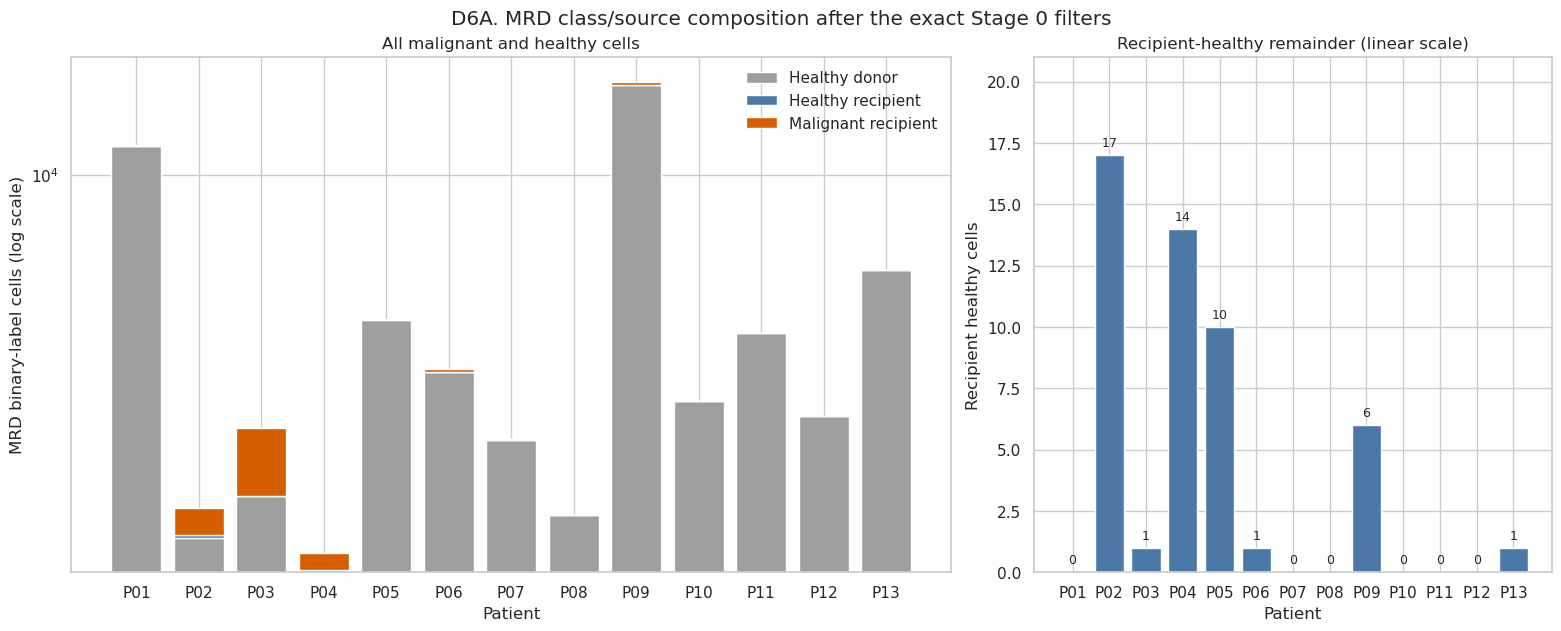

/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/meeting_followup_v1/D6B_patient_ap_vs_constant_baseline.png


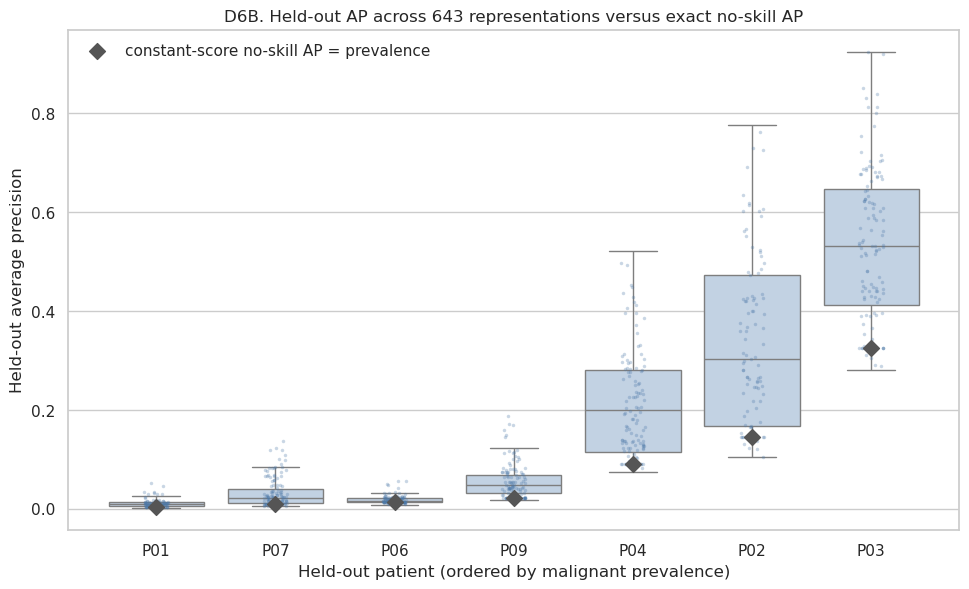

/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/meeting_followup_v1/D6C_raw_and_normalized_lift_by_patient.png


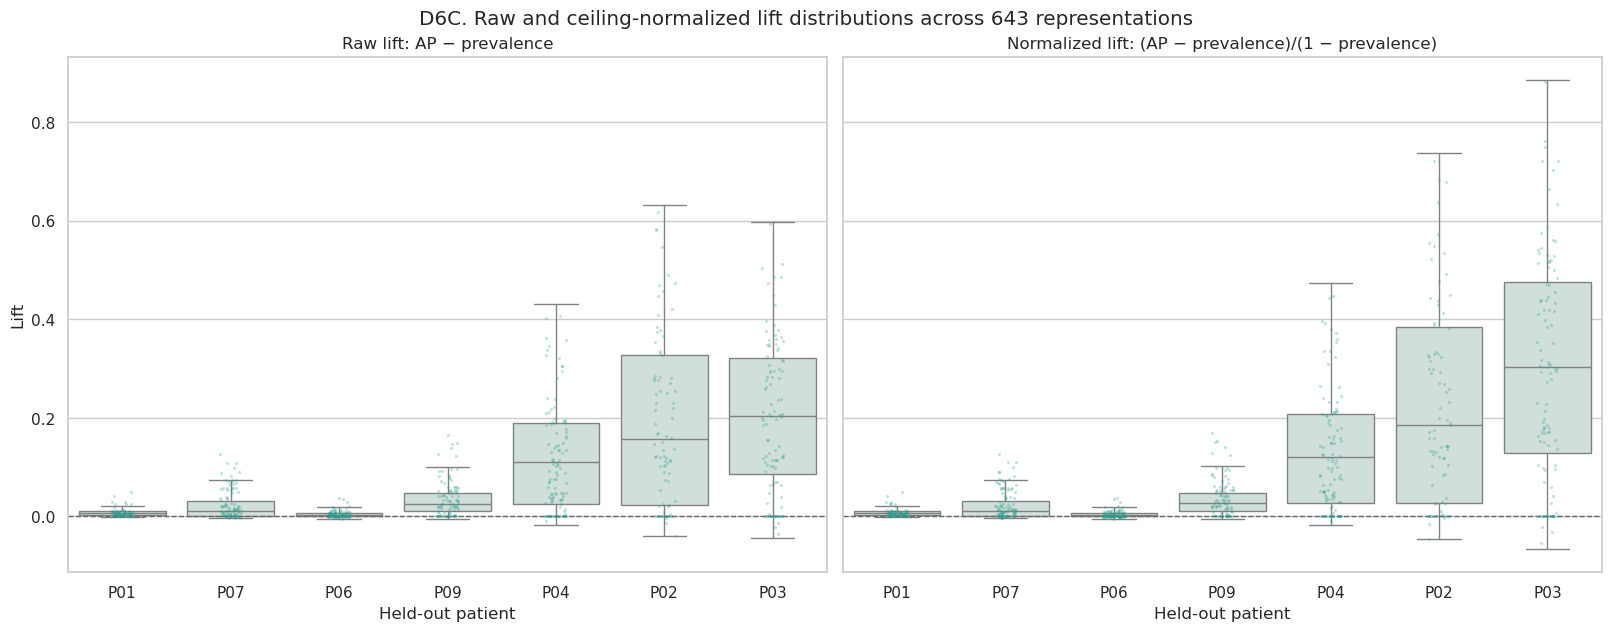

/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/meeting_followup_v1/D6D_metric_association_with_prevalence_and_counts.png


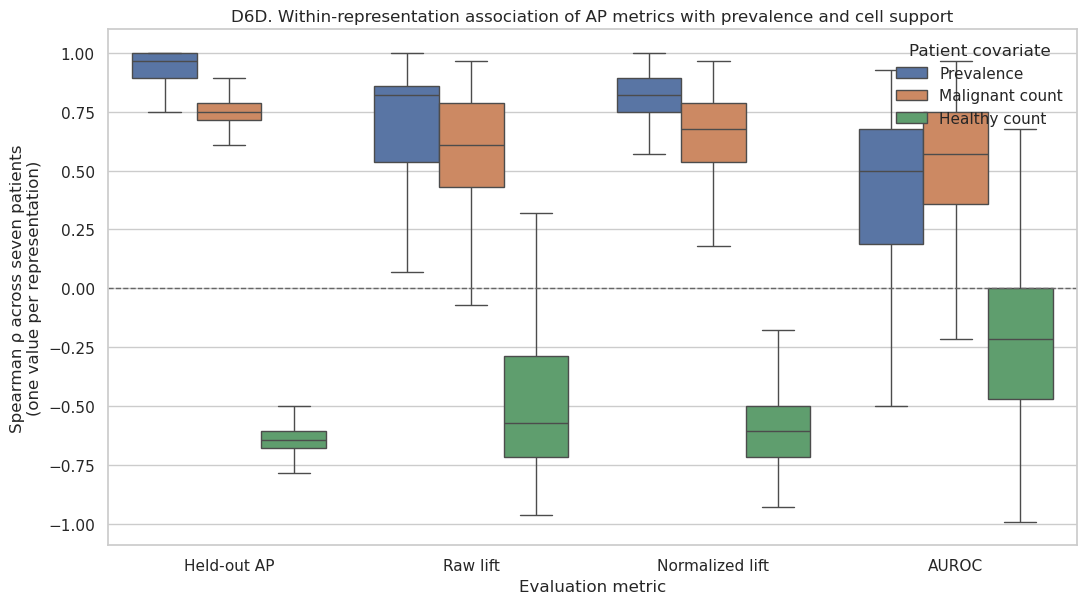

/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/meeting_followup_v1/D6E_dummy_policy_utility_comparison.png


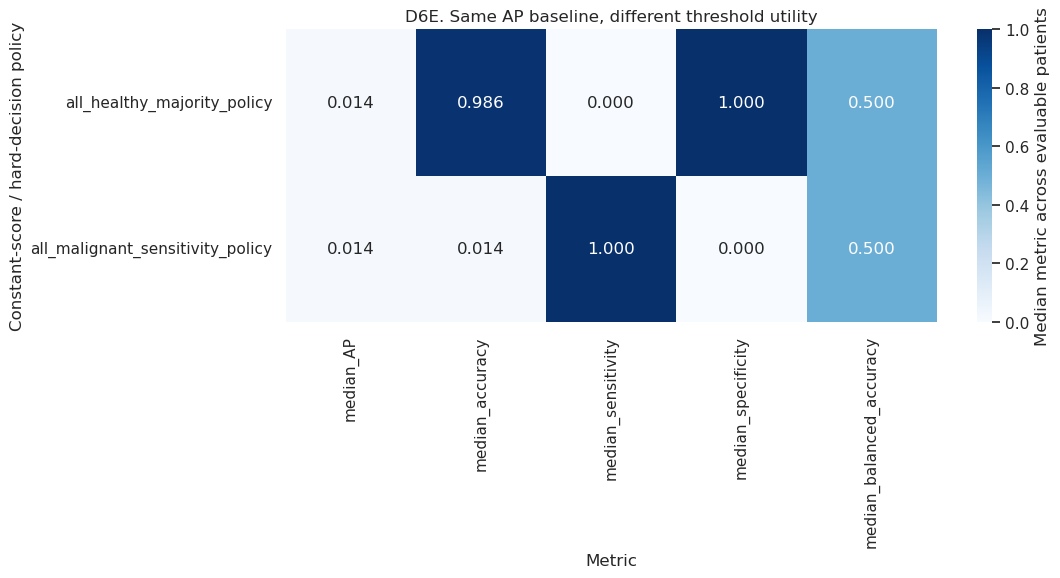

In [3]:
# D6A — MRD composition.
composition_plot = patient_composition.sort_values("patient_id").copy()
fig, axes = plt.subplots(1, 2, figsize=(15.5, 6.2), gridspec_kw={"width_ratios": [1.7, 1]}, constrained_layout=True)
bottom = np.zeros(len(composition_plot))
colors = {
    "n_healthy_donor": "#9E9E9E",
    "n_healthy_recipient": "#4C78A8",
    "n_malignant_recipient": "#D55E00",
}
labels = {
    "n_healthy_donor": "Healthy donor",
    "n_healthy_recipient": "Healthy recipient",
    "n_malignant_recipient": "Malignant recipient",
}
for column in ["n_healthy_donor", "n_healthy_recipient", "n_malignant_recipient"]:
    axes[0].bar(composition_plot["patient_id"], composition_plot[column], bottom=bottom, color=colors[column], label=labels[column])
    bottom += composition_plot[column].to_numpy()
axes[0].set_yscale("log")
axes[0].set_ylabel("MRD binary-label cells (log scale)")
axes[0].set_xlabel("Patient")
axes[0].set_title("All malignant and healthy cells")
axes[0].legend(frameon=False)
axes[1].bar(composition_plot["patient_id"], composition_plot["n_healthy_recipient"], color=colors["n_healthy_recipient"])
for x, value in enumerate(composition_plot["n_healthy_recipient"]):
    axes[1].text(x, value + 0.35, str(int(value)), ha="center", fontsize=9)
axes[1].set_ylim(0, max(20, composition_plot["n_healthy_recipient"].max() + 4))
axes[1].set_ylabel("Recipient healthy cells")
axes[1].set_xlabel("Patient")
axes[1].set_title("Recipient-healthy remainder (linear scale)")
fig.suptitle("D6A. MRD class/source composition after the exact Stage 0 filters")
d6a_png = save_figure(fig, "D6A_mrd_patient_cell_composition")
plt.show()

# D6B — held-out AP distributions and exact constant-score AP.
patient_order = patient_metric_summary.sort_values("prevalence")["heldout_patient"].tolist()
fig, ax = plt.subplots(figsize=(11.5, 6.5))
sns.boxplot(
    data=patient_metrics,
    x="heldout_patient",
    y="heldout_auprc",
    order=patient_order,
    color="#BCD2E8",
    showfliers=False,
    ax=ax,
)
sns.stripplot(
    data=patient_metrics.sample(frac=0.18, random_state=42),
    x="heldout_patient",
    y="heldout_auprc",
    order=patient_order,
    color="#4C78A8",
    alpha=0.30,
    size=2.5,
    ax=ax,
)
baseline_by_patient = patient_metric_summary.set_index("heldout_patient")["prevalence"]
for x, patient_id in enumerate(patient_order):
    ax.scatter(x, baseline_by_patient[patient_id], marker="D", s=65, color="#555555", zorder=5)
ax.scatter([], [], marker="D", s=65, color="#555555", label="constant-score no-skill AP = prevalence")
ax.set_xlabel("Held-out patient (ordered by malignant prevalence)")
ax.set_ylabel("Held-out average precision")
ax.set_title("D6B. Held-out AP across 643 representations versus exact no-skill AP")
ax.legend(frameon=False, loc="upper left")
d6b_png = save_figure(fig, "D6B_patient_ap_vs_constant_baseline")
plt.show()

# D6C — raw and ceiling-normalized lift.
lift_long = pd.concat(
    [
        patient_metrics[["heldout_patient", "heldout_lift"]].rename(columns={"heldout_lift": "value"}).assign(metric="Raw lift: AP − prevalence"),
        patient_metrics[["heldout_patient", "normalized_heldout_lift"]].rename(columns={"normalized_heldout_lift": "value"}).assign(metric="Normalized lift: (AP − prevalence)/(1 − prevalence)"),
    ],
    ignore_index=True,
)
fig, axes = plt.subplots(1, 2, figsize=(16, 6.2), sharey=True, constrained_layout=True)
for ax, metric_name in zip(axes, lift_long["metric"].drop_duplicates()):
    subset = lift_long.loc[lift_long["metric"].eq(metric_name)]
    sns.boxplot(data=subset, x="heldout_patient", y="value", order=patient_order, color="#CDE1D9", showfliers=False, ax=ax)
    sns.stripplot(data=subset.sample(frac=0.15, random_state=42), x="heldout_patient", y="value", order=patient_order, color="#2A9D8F", alpha=0.28, size=2.3, ax=ax)
    ax.axhline(0, color="0.4", lw=1, ls="--")
    ax.set_xlabel("Held-out patient")
    ax.set_ylabel("Lift")
    ax.set_title(metric_name)
fig.suptitle("D6C. Raw and ceiling-normalized lift distributions across 643 representations")
d6c_png = save_figure(fig, "D6C_raw_and_normalized_lift_by_patient")
plt.show()

# D6D — within-representation rank association with prevalence/cell support.
association_plot = metric_prevalence_association.copy()
metric_labels = {
    "heldout_auprc": "Held-out AP",
    "heldout_lift": "Raw lift",
    "normalized_heldout_lift": "Normalized lift",
    "heldout_auroc": "AUROC",
}
covariate_labels = {
    "patient_prevalence": "Prevalence",
    "n_malignant_h": "Malignant count",
    "n_normal_h": "Healthy count",
}
association_plot["metric_label"] = association_plot["metric"].map(metric_labels)
association_plot["covariate_label"] = association_plot["covariate"].map(covariate_labels)
fig, ax = plt.subplots(figsize=(12.5, 6.7))
sns.boxplot(
    data=association_plot,
    x="metric_label",
    y="spearman_rho_across_7_patients",
    hue="covariate_label",
    showfliers=False,
    ax=ax,
)
ax.axhline(0, color="0.4", lw=1, ls="--")
ax.set_xlabel("Evaluation metric")
ax.set_ylabel("Spearman ρ across seven patients\n(one value per representation)")
ax.set_title("D6D. Within-representation association of AP metrics with prevalence and cell support")
ax.legend(title="Patient covariate", frameon=False, loc="upper right")
d6d_png = save_figure(fig, "D6D_metric_association_with_prevalence_and_counts")
plt.show()

# D6E — hard-policy utility is separate from AP.
policy_summary = (
    dummy_policy_metrics.groupby("policy", as_index=False)
    .agg(
        median_AP=("constant_score_average_precision", "median"),
        median_accuracy=("accuracy", "median"),
        median_sensitivity=("malignant_sensitivity", "median"),
        median_specificity=("healthy_specificity", "median"),
        median_balanced_accuracy=("balanced_accuracy", "median"),
    )
    .set_index("policy")
)
fig, ax = plt.subplots(figsize=(10.5, 3.8))
sns.heatmap(policy_summary, annot=True, fmt=".3f", cmap="Blues", vmin=0, vmax=1, cbar_kws={"label": "Median metric across evaluable patients"}, ax=ax)
ax.set_xlabel("Metric")
ax.set_ylabel("Constant-score / hard-decision policy")
ax.set_title("D6E. Same AP baseline, different threshold utility")
d6e_png = save_figure(fig, "D6E_dummy_policy_utility_comparison")
plt.show()

## 3. D7 — patient × gene-set × DR interactions

The prior D1c atlases already contain all 643 representations for each supported patient. D7 adds contrasts that are easier to judge manually:

- PCA-40 minus FA-40 lift for every panel and patient.
- Maximum K=40 lift spread across PCA, FA, FactoSig, and promax FactoSig.
- IFN-α method-by-K trajectories for all seven patients.
- The same method-by-K trajectories for the D7B hotspot panels: MHC class I antigen presentation, epithelial mesenchymal transition, and interferon gamma signaling.
- How D7B uses Stage 2: one globally selected regularization per representation (L1, L2, or elastic net), versus the same K=40 method-spread under L1-only, L2-only, and per-patient best transfer.
- A concrete IFN-α PCA-40 versus FA-40 comparison.

A positive PCA−FA contrast means PCA has higher held-out AP lift under each representation's globally selected pooled-LOPO regularization.

In [4]:
dr_methods = ["pca", "fa", "factosig", "factosig_promax"]
k40 = patient_metrics.loc[
    patient_metrics["effective_k"].eq(40) & patient_metrics["stage1_method"].isin(dr_methods)
].copy()

pca_fa_wide = (
    k40.loc[k40["stage1_method"].isin(["pca", "fa"])]
    .pivot_table(
        index=["stage0_panel_id", "panel_label_with_genes", "heldout_patient"],
        columns="stage1_method",
        values="heldout_lift",
        aggfunc="first",
    )
    .reset_index()
)
pca_fa_wide["pca40_minus_fa40_lift"] = pca_fa_wide["pca"] - pca_fa_wide["fa"]
pca_fa_path = write_csv(pca_fa_wide, "old34_pca40_minus_fa40_patient_lift.csv")

method_spread = (
    k40.groupby(
        ["stage0_panel_id", "panel_label_with_genes", "heldout_patient"],
        as_index=False,
    )
    .agg(
        min_method_lift=("heldout_lift", "min"),
        max_method_lift=("heldout_lift", "max"),
        mean_method_lift=("heldout_lift", "mean"),
        n_methods=("stage1_method", "nunique"),
    )
)
method_spread["k40_method_lift_range"] = method_spread["max_method_lift"] - method_spread["min_method_lift"]
method_spread_path = write_csv(method_spread, "old34_k40_method_lift_spread_by_patient.csv")

def extract_panel_method_k_metrics(panel_id: str, csv_name: str) -> pd.DataFrame:
    frame = patient_metrics.loc[
        patient_metrics["stage0_panel_id"].eq(panel_id)
        & patient_metrics["stage1_method"].isin(dr_methods)
    ].copy()
    write_csv(frame, csv_name)
    return frame


ifna_patient = extract_panel_method_k_metrics(IFNA_PANEL, "interferon_alpha_all_method_k_patient_metrics.csv")
mhci_patient = extract_panel_method_k_metrics(MHCI_PANEL, "mhc_class_i_all_method_k_patient_metrics.csv")
emt_patient = extract_panel_method_k_metrics(
    EMT_PANEL, "epithelial_mesenchymal_transition_all_method_k_patient_metrics.csv"
)
ifng_patient = extract_panel_method_k_metrics(
    IFNG_SIGNALING_PANEL, "interferon_gamma_signaling_all_method_k_patient_metrics.csv"
)
ifna_pca_fa40 = ifna_patient.loc[
    ifna_patient["effective_k"].eq(40) & ifna_patient["stage1_method"].isin(["pca", "fa"])
].copy()
ifna_pca_fa40_path = write_csv(
    ifna_pca_fa40,
    "interferon_alpha_pca40_fa40_patient_comparison.csv",
)

high_spread_k40 = (
    k40.loc[k40["stage0_panel_id"].isin([MHCI_PANEL, EMT_PANEL, IFNG_SIGNALING_PANEL])]
    .pivot_table(
        index=["short_panel_label", "heldout_patient"],
        columns="stage1_method",
        values="heldout_lift_percentage_points",
        aggfunc="first",
    )
    .reindex(columns=dr_methods)
)
high_spread_k40["k40_method_lift_range"] = high_spread_k40.max(axis=1) - high_spread_k40.min(axis=1)
high_spread_k40 = high_spread_k40.reset_index()
high_spread_k40_path = write_csv(high_spread_k40, "old34_d7b_high_spread_k40_method_lifts.csv")
print("D7B hotspot panels at K=40 (AUPRC percentage points)")
display(high_spread_k40.round(2))

# D7B Stage 2 policy: one frozen pooled-LOPO regularization per representation, not L1-only,
# L2-only, or per-patient best transfer. Rebuild K=40 method spreads under those alternatives.
STAGE2_POLICY_ORDER = ["selected_mixed", "best_l1", "best_l2", "patient_oracle"]
STAGE2_POLICY_LABELS = {
    "selected_mixed": "Globally selected mixed (current D7B)",
    "best_l1": "Best L1 by pooled LOPO",
    "best_l2": "Best L2 by pooled LOPO",
    "patient_oracle": "Patient-wise best transfer",
}
D7B_HOTSPOT_PANELS = [MHCI_PANEL, EMT_PANEL, IFNG_SIGNALING_PANEL]


def pick_best_pooled_regularization(frame: pd.DataFrame, penalty: str | None = None) -> pd.DataFrame:
    subset = frame if penalty is None else frame.loc[frame["penalty"].eq(penalty)]
    return (
        subset.sort_values(["lopo_auprc_pooled", "stage2_regularization"], ascending=[False, True])
        .groupby(["stage0_panel_id", "stage1_method"], as_index=False)
        .first()
        [["stage0_panel_id", "stage1_method", "penalty", "stage2_regularization", "lopo_auprc_pooled"]]
    )


k40_rep = representation.loc[
    representation["effective_k"].eq(40) & representation["stage1_method"].isin(dr_methods)
].copy()
lopo_pooled = pd.read_csv(
    SOURCE_PATHS["lopo_pooled_by_regularization"],
    usecols=[
        "stage0_panel_id",
        "stage1_method",
        "stage1_method_k",
        "penalty",
        "stage2_regularization",
        "lopo_auprc_pooled",
    ],
    low_memory=False,
)
lopo_pooled = lopo_pooled.loc[
    lopo_pooled["stage1_method_k"].eq(40) & lopo_pooled["stage1_method"].isin(dr_methods)
].copy()
best_any = pick_best_pooled_regularization(lopo_pooled)
best_l1 = pick_best_pooled_regularization(lopo_pooled, "l1")
best_l2 = pick_best_pooled_regularization(lopo_pooled, "l2")
selected_vs_pooled = k40_rep.merge(
    best_any,
    on=["stage0_panel_id", "stage1_method"],
    how="left",
    validate="one_to_one",
)
assert selected_vs_pooled["selected_stage2_regularization"].eq(selected_vs_pooled["stage2_regularization"]).all()

patientwise_cols = [
    "stage0_panel_id",
    "short_panel_label",
    "stage1_method",
    "stage1_method_k",
    "penalty",
    "stage2_regularization",
    "heldout_patient",
    "heldout_lift",
    "supported_patient",
    "nonzero_coefficient_count",
]
patientwise_chunks = []
for chunk in pd.read_csv(
    SOURCE_PATHS["lopo_patientwise_by_regularization"],
    usecols=patientwise_cols,
    chunksize=100_000,
    low_memory=False,
):
    if chunk["supported_patient"].dtype != bool:
        chunk["supported_patient"] = chunk["supported_patient"].astype(str).str.lower().eq("true")
    patientwise_chunks.append(
        chunk.loc[
            chunk["stage1_method_k"].eq(40)
            & chunk["stage1_method"].isin(dr_methods)
            & chunk["supported_patient"]
            & chunk["heldout_patient"].isin(SUPPORTED_PATIENTS)
        ]
    )
k40_all_regs = pd.concat(patientwise_chunks, ignore_index=True)
panel_labels = k40_rep[["stage0_panel_id", "panel_label_with_genes"]].drop_duplicates()
k40_all_regs = k40_all_regs.merge(panel_labels, on="stage0_panel_id", how="left")


def slice_policy(keys: pd.DataFrame, policy: str) -> pd.DataFrame:
    out = k40_all_regs.merge(
        keys[["stage0_panel_id", "stage1_method", "stage2_regularization"]],
        on=["stage0_panel_id", "stage1_method", "stage2_regularization"],
        how="inner",
    )
    out["stage2_policy"] = policy
    return out


selected_keys = k40_rep.rename(columns={"selected_stage2_regularization": "stage2_regularization"})[
    ["stage0_panel_id", "stage1_method", "stage2_regularization", "selected_penalty"]
]
policy_patient = pd.concat(
    [
        slice_policy(selected_keys, "selected_mixed"),
        slice_policy(best_l1, "best_l1"),
        slice_policy(best_l2, "best_l2"),
        k40_all_regs.sort_values(["heldout_lift", "stage2_regularization"], ascending=[False, True])
        .groupby(["stage0_panel_id", "stage1_method", "heldout_patient"], as_index=False)
        .first()
        .assign(stage2_policy="patient_oracle"),
    ],
    ignore_index=True,
)
policy_patient["heldout_lift_percentage_points"] = 100 * policy_patient["heldout_lift"]
policy_patient_path = write_csv(policy_patient, "old34_k40_method_lift_by_stage2_policy.csv")

policy_spread = (
    policy_patient.groupby(
        ["stage2_policy", "stage0_panel_id", "panel_label_with_genes", "heldout_patient"],
        as_index=False,
    )
    .agg(
        min_method_lift=("heldout_lift", "min"),
        max_method_lift=("heldout_lift", "max"),
        n_methods=("stage1_method", "nunique"),
    )
)
policy_spread["k40_method_lift_range"] = policy_spread["max_method_lift"] - policy_spread["min_method_lift"]
policy_spread_path = write_csv(policy_spread, "old34_k40_method_spread_by_stage2_policy.csv")

k40_selected_penalty = k40_rep[
    ["stage0_panel_id", "panel_label_with_genes", "stage1_method", "selected_penalty", "selected_stage2_regularization", "selected_C_or_alpha", "selected_l1_ratio"]
].copy()
k40_selected_sparsity = (
    policy_patient.loc[policy_patient["stage2_policy"].eq("selected_mixed")]
    .groupby(["stage0_panel_id", "panel_label_with_genes", "stage1_method"], as_index=False)
    .agg(
        median_nonzero_coefficients=("nonzero_coefficient_count", "median"),
        min_nonzero_coefficients=("nonzero_coefficient_count", "min"),
        max_nonzero_coefficients=("nonzero_coefficient_count", "max"),
    )
)
k40_selected_usage = k40_selected_penalty.merge(
    k40_selected_sparsity,
    on=["stage0_panel_id", "panel_label_with_genes", "stage1_method"],
    how="left",
    validate="one_to_one",
)
k40_selected_usage_path = write_csv(k40_selected_usage, "old34_k40_selected_stage2_penalty_and_sparsity.csv")

assert len(best_l1) == len(k40_rep)
assert len(best_l2) == len(k40_rep)
assert policy_patient["stage2_policy"].nunique() == 4
print("K=40 DR selected Stage 2 penalties:")
print(k40_rep["selected_penalty"].value_counts().to_string())
print("D7B method-spread median (AUPRC pp) by Stage 2 policy:")
print(
    (100 * policy_spread.groupby("stage2_policy")["k40_method_lift_range"].median())
    .reindex(STAGE2_POLICY_ORDER)
    .round(2)
    .to_string()
)
display(
    k40_selected_usage.loc[k40_selected_usage["stage0_panel_id"].isin(D7B_HOTSPOT_PANELS)]
    .sort_values(["panel_label_with_genes", "stage1_method"])
    [["panel_label_with_genes", "stage1_method", "selected_penalty", "selected_stage2_regularization", "median_nonzero_coefficients"]]
)

panel_base = (
    representation.sort_values("stage0_panel_id")
    .drop_duplicates("stage0_panel_id")
    [["stage0_panel_id", "short_panel_label", "biological_theme", "n_covered_genes"]]
)
direct_ids = set(representation.loc[representation["stage1_method"].eq("direct_gene"), "stage0_panel_id"])
direct_coverage = panel_base.copy()
direct_coverage["has_completed_direct_gene_baseline"] = direct_coverage["stage0_panel_id"].isin(direct_ids)
direct_coverage["direct_gene_gap_status"] = np.where(
    direct_coverage["has_completed_direct_gene_baseline"],
    "completed_small_panel_fallback",
    "missing_direct_gene_baseline",
)
direct_coverage["priority_panel"] = direct_coverage["stage0_panel_id"].isin(
    {
        "single_group__stress_arrest",
        "single_geneset__hallmark_p53_pathway",
        IFNA_PANEL,
    }
)
direct_coverage_path = write_csv(direct_coverage, "old34_direct_gene_baseline_coverage.csv")

assert len(direct_ids) == 3
assert not direct_coverage.loc[direct_coverage["stage0_panel_id"].eq(IFNA_PANEL), "has_completed_direct_gene_baseline"].iloc[0]
print("Current direct-gene baselines:", len(direct_ids), "/ 41 panels")
display(direct_coverage.loc[direct_coverage["priority_panel"]])

D7B hotspot panels at K=40 (AUPRC percentage points)


stage1_method,short_panel_label,heldout_patient,pca,fa,factosig,factosig_promax,k40_method_lift_range
0,epithelial mesenchymal transition,P01,-0.00,-0.00,1.47,0.57,1.47
1,epithelial mesenchymal transition,P02,11.09,10.77,49.25,44.74,38.48
2,epithelial mesenchymal transition,P03,9.24,18.62,18.18,1.83,16.80
3,epithelial mesenchymal transition,P04,0.95,1.05,4.85,5.94,4.99
4,epithelial mesenchymal transition,P06,-0.09,0.69,0.97,0.92,1.06
5,epithelial mesenchymal transition,P07,9.24,9.73,16.63,19.02,9.78
6,epithelial mesenchymal transition,P09,-0.00,-0.00,3.32,8.57,8.57
7,interferon gamma signaling,P01,0.57,-0.00,0.48,0.72,0.72
8,interferon gamma signaling,P02,14.48,-0.00,28.20,33.13,33.13
9,interferon gamma signaling,P03,16.67,-3.72,21.38,27.52,31.24


Current direct-gene baselines: 3 / 41 panels


,stage0_panel_id,short_panel_label,biological_theme,n_covered_genes,has_completed_direct_gene_baseline,direct_gene_gap_status,priority_panel
201,single_geneset__hallmark_interferon_alpha_response,interferon alpha response,interferon,92,False,missing_direct_gene_baseline,True
302,single_geneset__hallmark_p53_pathway,p53 pathway,other,164,False,missing_direct_gene_baseline,True
626,single_group__stress_arrest,stress arrest,hypoxia_stress,685,False,missing_direct_gene_baseline,True


/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/meeting_followup_v1/D7A_pca40_minus_fa40_lift_heatmap.png


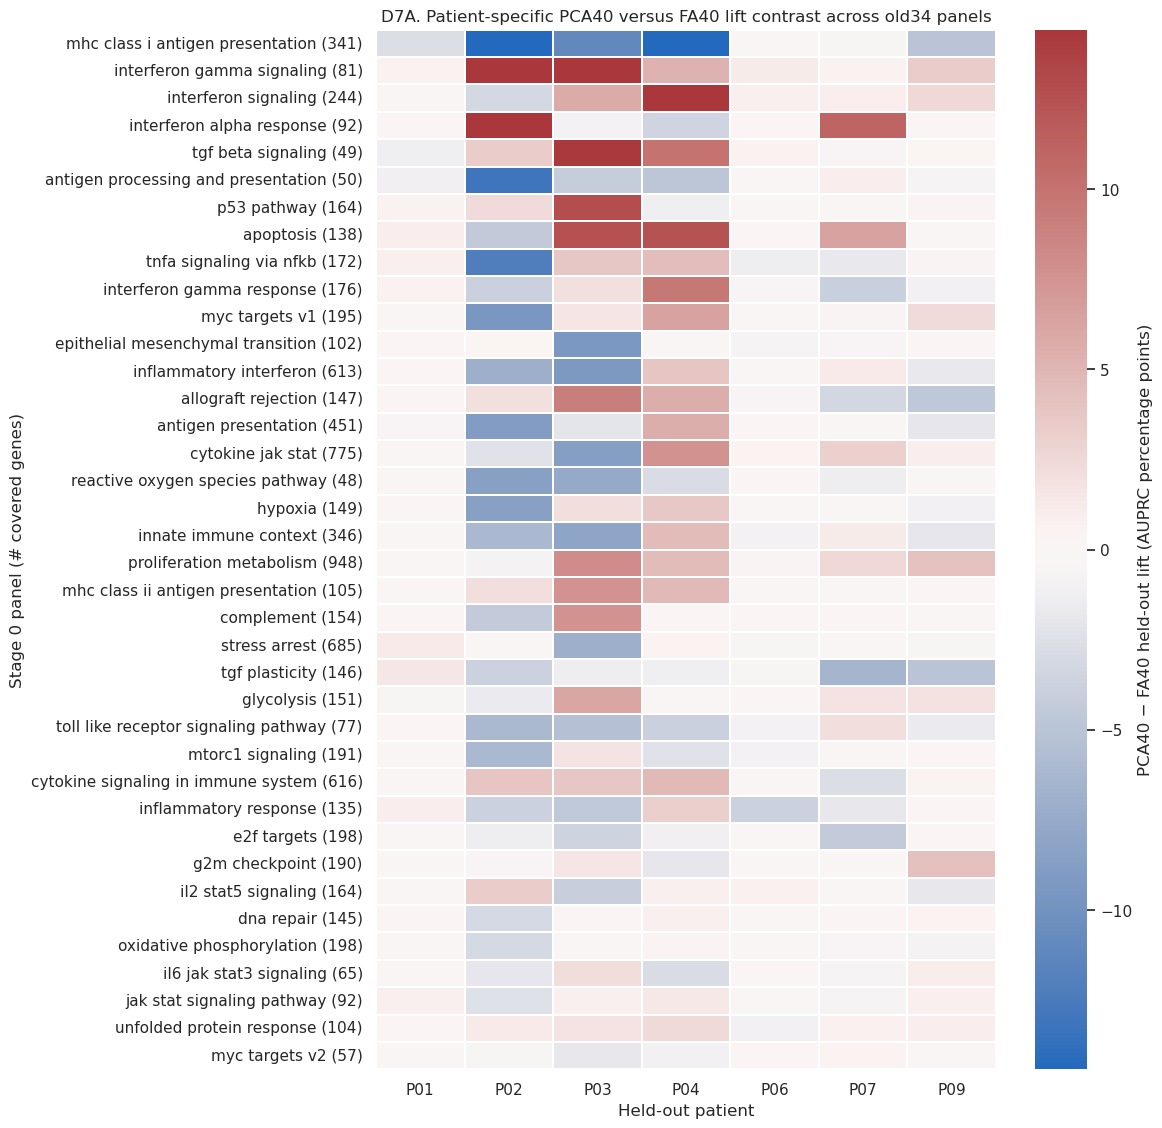

/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/meeting_followup_v1/D7B_k40_method_interaction_range_heatmap.png


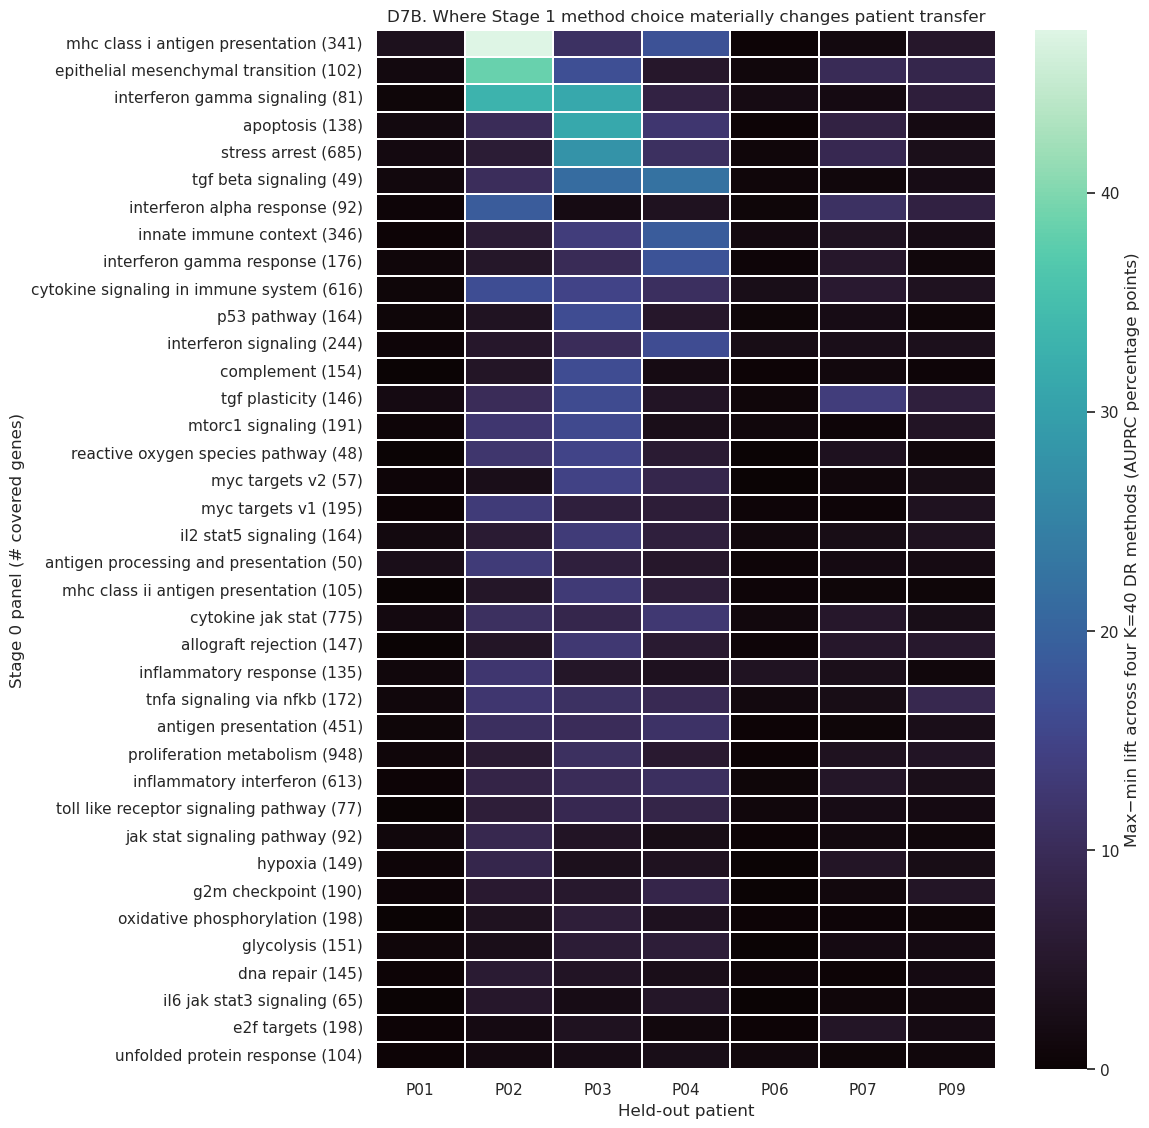

/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/meeting_followup_v1/D7C_interferon_alpha_method_k_patient_trajectories.png


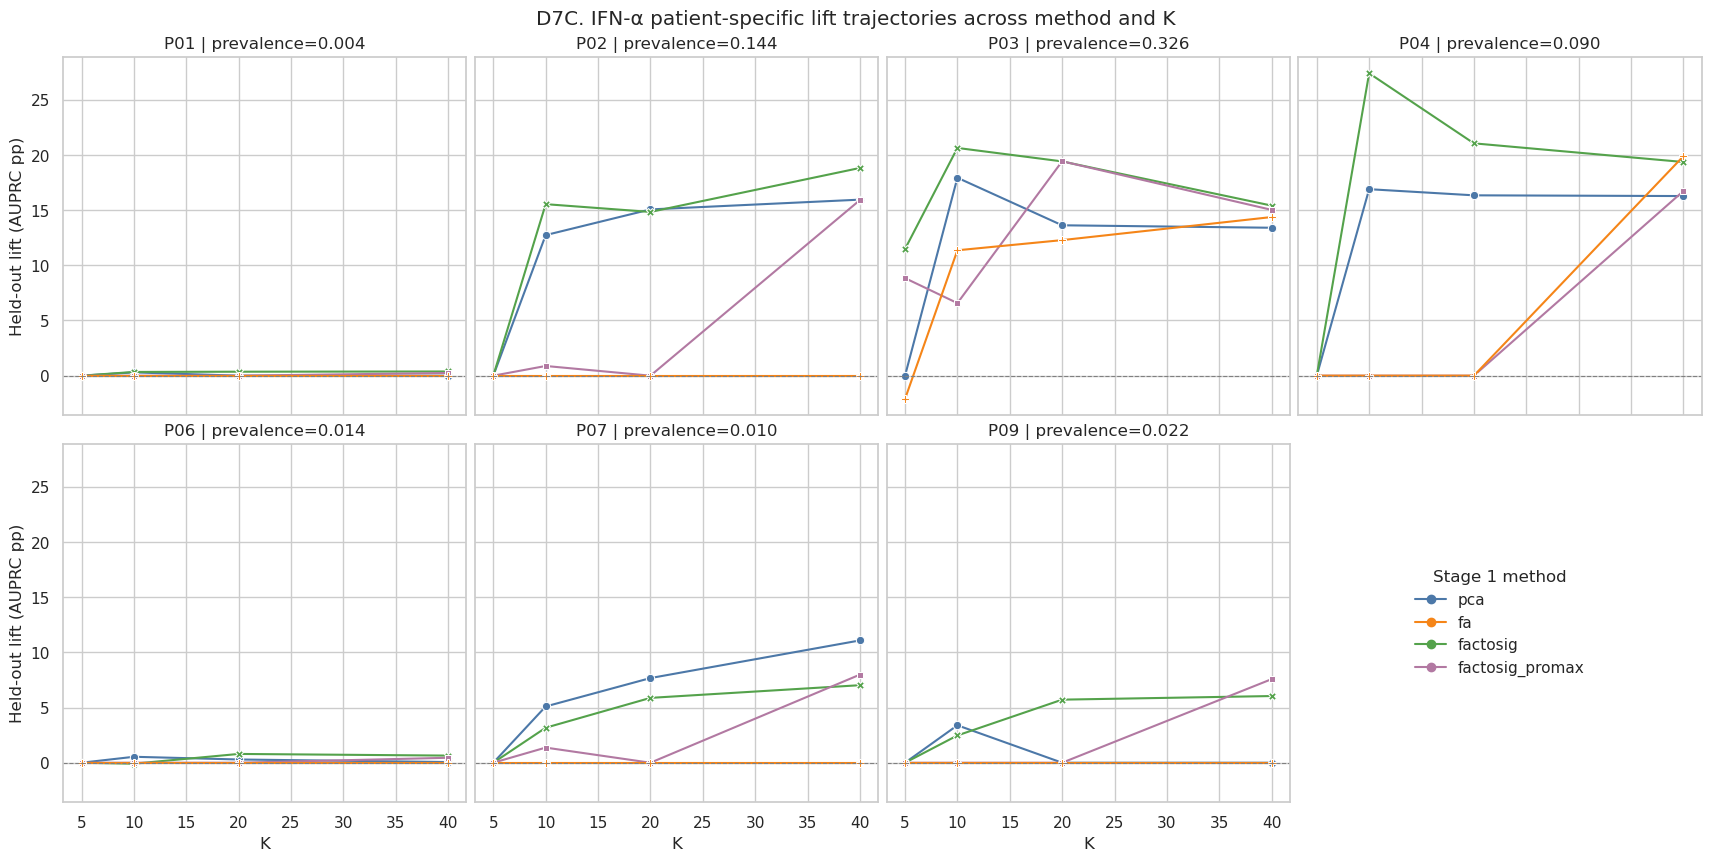

/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/meeting_followup_v1/D7D_interferon_alpha_pca40_vs_fa40.png


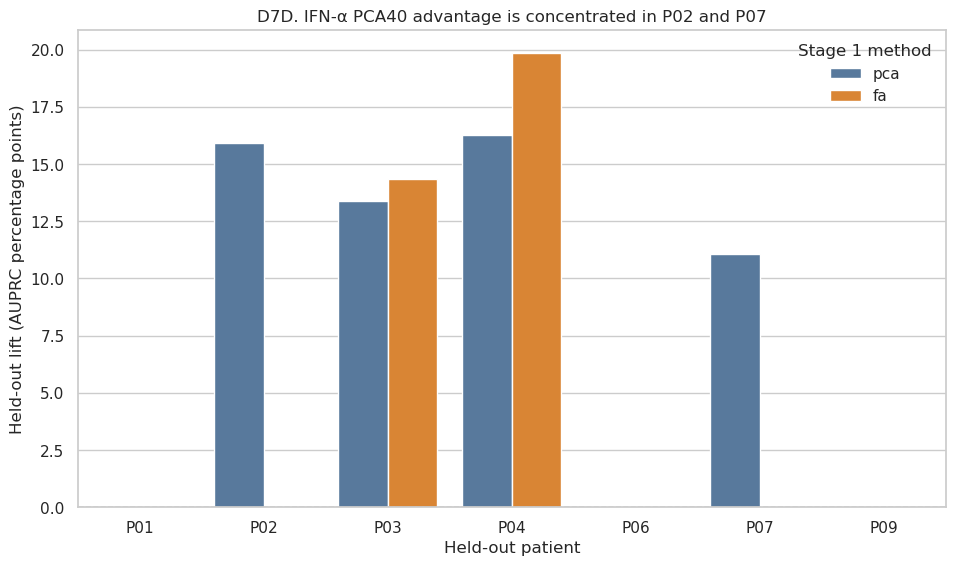

/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/meeting_followup_v1/D7E_direct_gene_baseline_coverage_gap.png


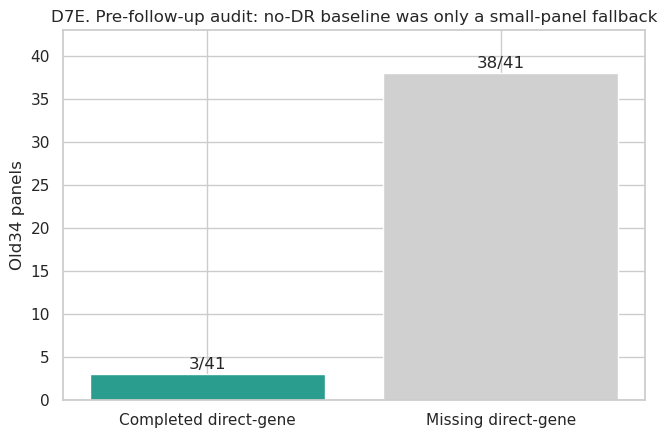

/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/meeting_followup_v1/D7F_mhc_class_i_method_k_patient_trajectories.png


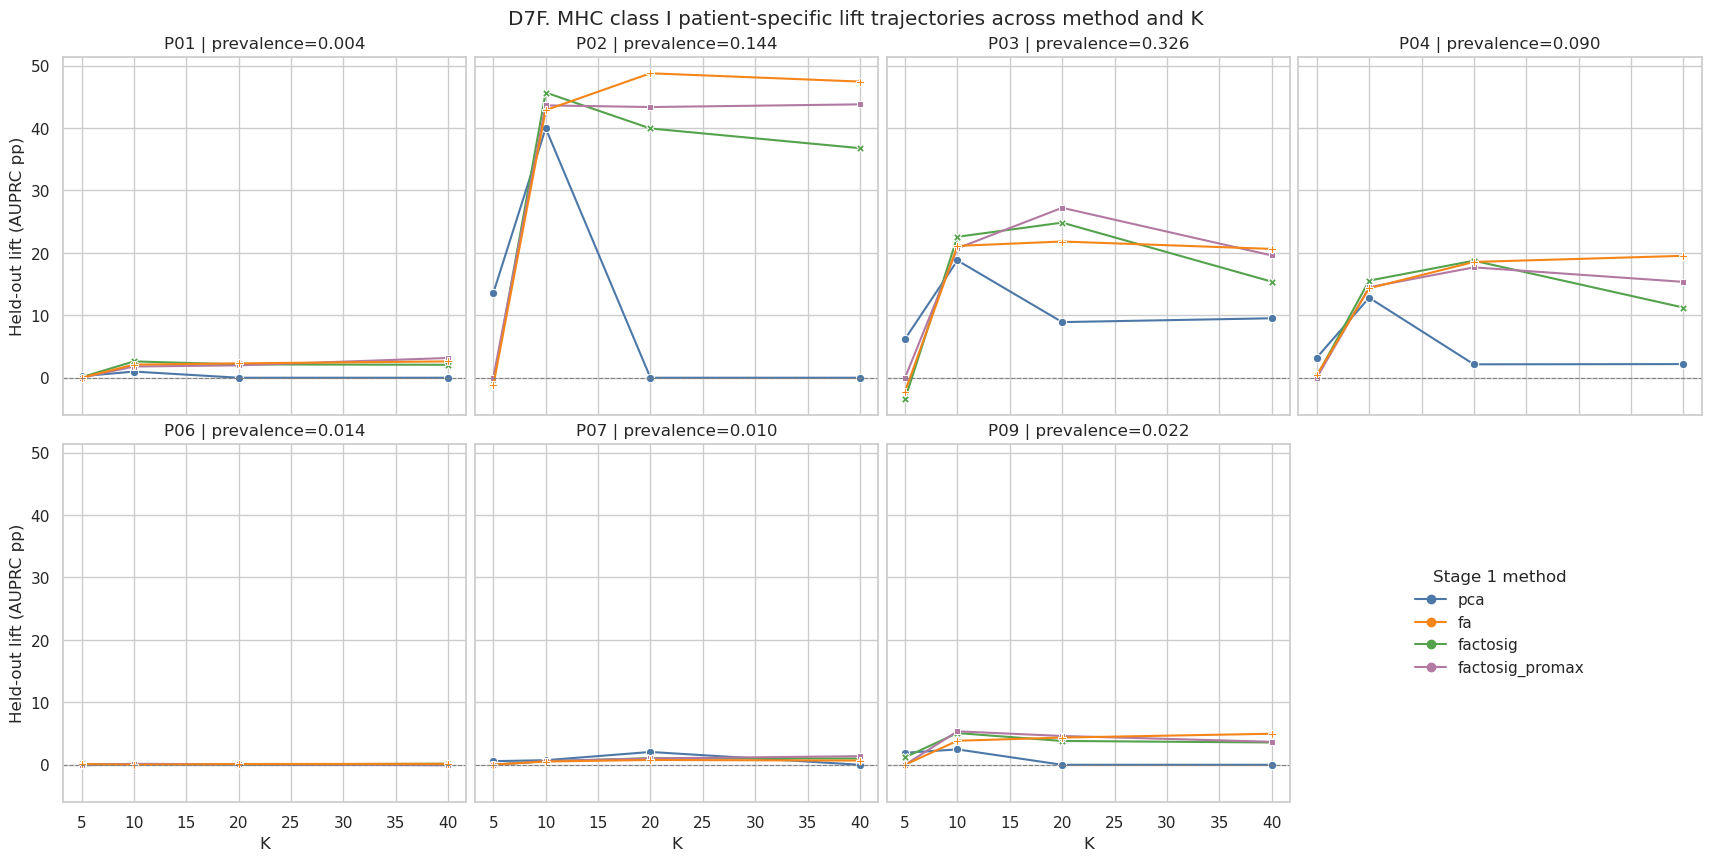

/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/meeting_followup_v1/D7G_epithelial_mesenchymal_transition_method_k_patient_trajectories.png


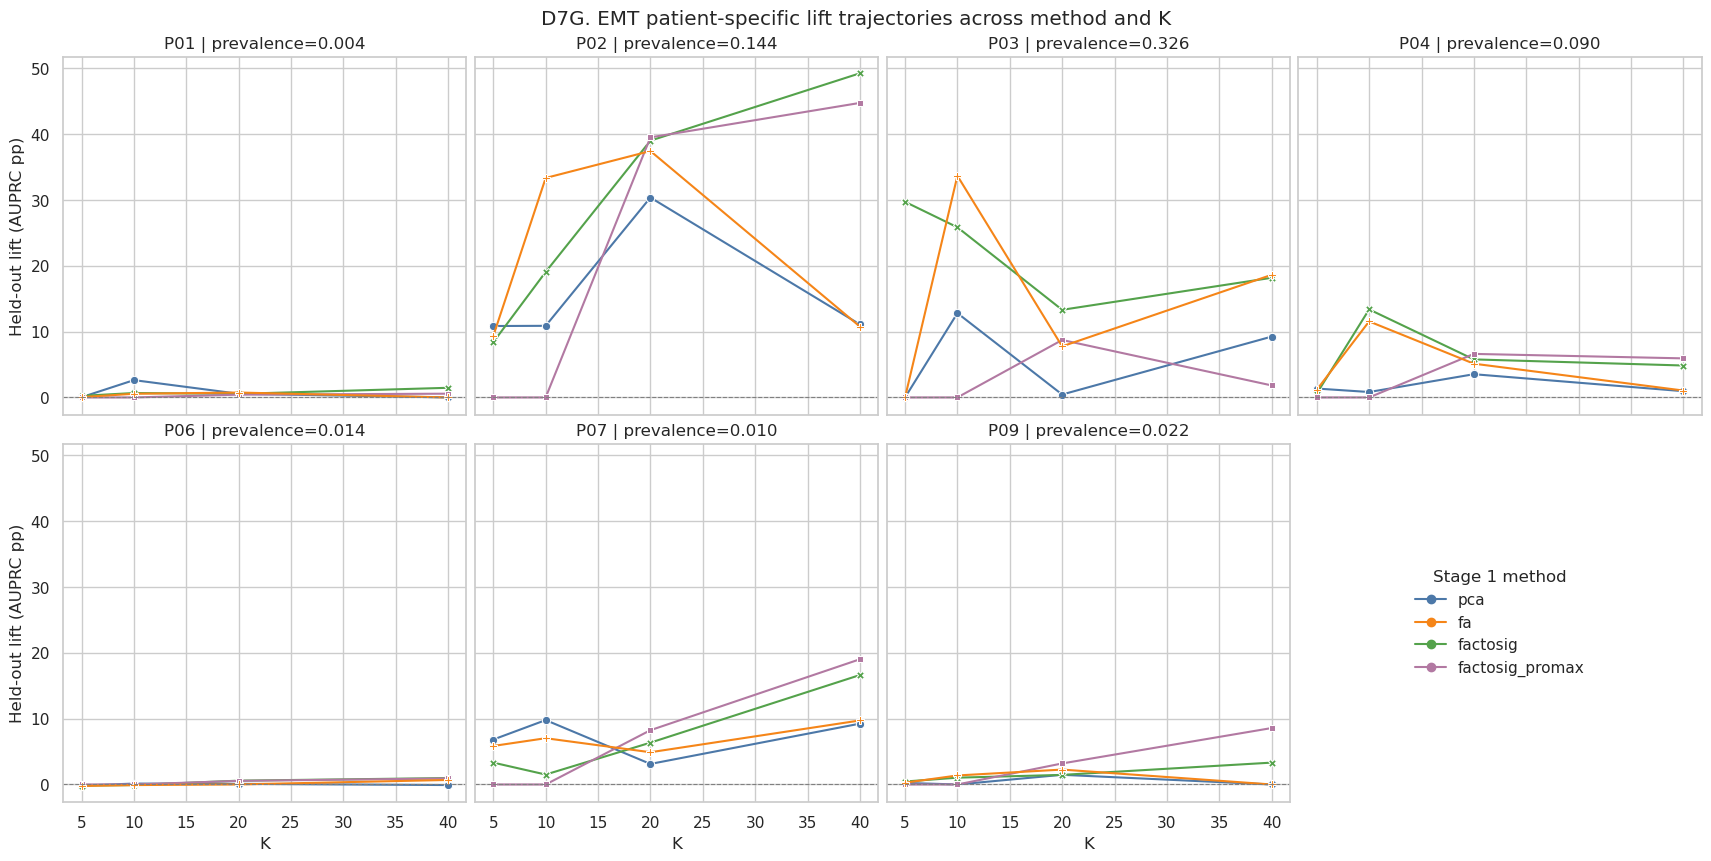

/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/meeting_followup_v1/D7H_interferon_gamma_signaling_method_k_patient_trajectories.png


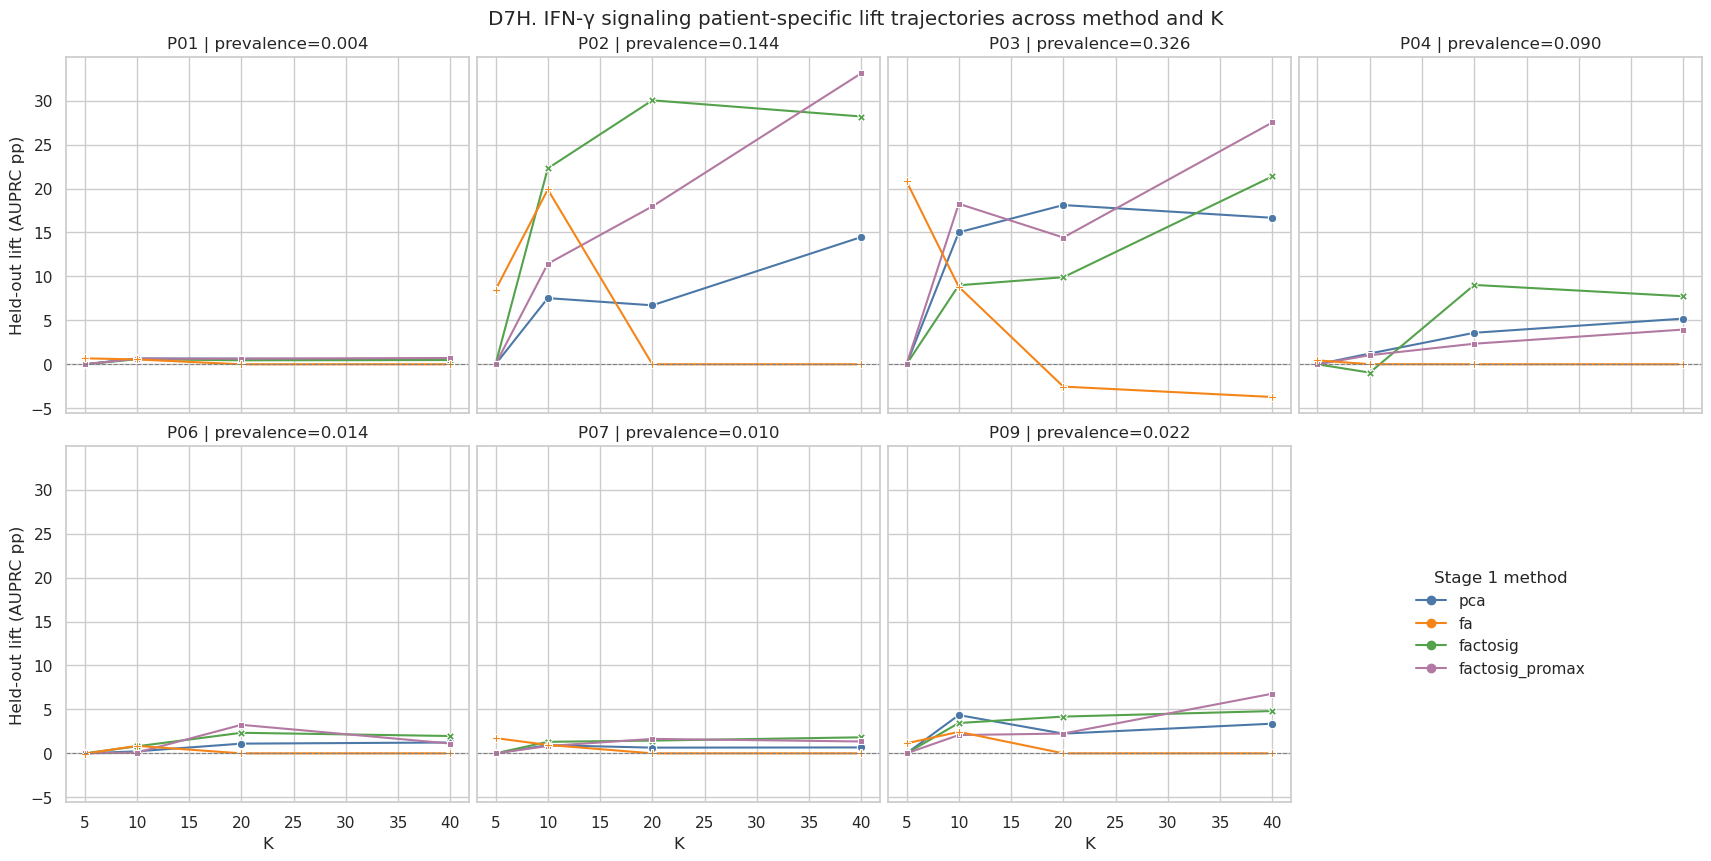

In [5]:
# D7A — PCA40 minus FA40 lift heatmap.
delta_matrix = pca_fa_wide.pivot(
    index="panel_label_with_genes",
    columns="heldout_patient",
    values="pca40_minus_fa40_lift",
).reindex(columns=SUPPORTED_PATIENTS)
delta_order = delta_matrix.abs().max(axis=1).sort_values(ascending=False).index
delta_matrix = delta_matrix.loc[delta_order]
vmax = max(float(np.nanpercentile(np.abs(delta_matrix.to_numpy()), 98)), 0.01)
fig, ax = plt.subplots(figsize=(10.0, 13.5))
sns.heatmap(
    100 * delta_matrix,
    cmap="vlag",
    center=0,
    vmin=-100 * vmax,
    vmax=100 * vmax,
    linewidths=0.25,
    linecolor="white",
    cbar_kws={"label": "PCA40 − FA40 held-out lift (AUPRC percentage points)"},
    ax=ax,
)
ax.set_xlabel("Held-out patient")
ax.set_ylabel("Stage 0 panel (# covered genes)")
ax.set_title("D7A. Patient-specific PCA40 versus FA40 lift contrast across old34 panels")
d7a_png = save_figure(fig, "D7A_pca40_minus_fa40_lift_heatmap")
plt.show()

# D7B — maximum method spread at K=40.
spread_matrix = method_spread.pivot(
    index="panel_label_with_genes",
    columns="heldout_patient",
    values="k40_method_lift_range",
).reindex(columns=SUPPORTED_PATIENTS)
spread_order = spread_matrix.max(axis=1).sort_values(ascending=False).index
spread_matrix = spread_matrix.loc[spread_order]
fig, ax = plt.subplots(figsize=(10.0, 13.5))
sns.heatmap(
    100 * spread_matrix,
    cmap="mako",
    vmin=0,
    linewidths=0.25,
    linecolor="white",
    cbar_kws={"label": "Max−min lift across four K=40 DR methods (AUPRC percentage points)"},
    ax=ax,
)
ax.set_xlabel("Held-out patient")
ax.set_ylabel("Stage 0 panel (# covered genes)")
ax.set_title("D7B. Where Stage 1 method choice materially changes patient transfer")
d7b_png = save_figure(fig, "D7B_k40_method_interaction_range_heatmap")
plt.show()

# D7C — IFN-alpha method-by-K trajectories for all supported patients.
method_palette = {"pca": "#4C78A8", "fa": "#F58518", "factosig": "#54A24B", "factosig_promax": "#B279A2"}


def plot_method_k_patient_trajectories(frame: pd.DataFrame, title: str, stem: str):
    fig, axes = plt.subplots(2, 4, figsize=(17, 8.5), sharex=True, sharey=True, constrained_layout=True)
    for ax, patient_id in zip(axes.flat, SUPPORTED_PATIENTS):
        subset = frame.loc[frame["heldout_patient"].eq(patient_id)].sort_values("effective_k")
        sns.lineplot(
            data=subset,
            x="effective_k",
            y="heldout_lift_percentage_points",
            hue="stage1_method",
            style="stage1_method",
            palette=method_palette,
            markers=True,
            dashes=False,
            ax=ax,
            legend=False,
        )
        ax.axhline(0, color="0.5", lw=0.8, ls="--")
        prevalence = subset["patient_prevalence"].iloc[0]
        ax.set_title(f"{patient_id} | prevalence={prevalence:.3f}")
        ax.set_xlabel("K")
        ax.set_ylabel("Held-out lift (AUPRC pp)")
    axes.flat[-1].axis("off")
    handles = [plt.Line2D([], [], color=color, marker="o", label=method) for method, color in method_palette.items()]
    axes.flat[-1].legend(handles=handles, loc="center", frameon=False, title="Stage 1 method")
    fig.suptitle(title)
    png = save_figure(fig, stem)
    plt.show()
    return png


d7c_png = plot_method_k_patient_trajectories(
    ifna_patient,
    "D7C. IFN-α patient-specific lift trajectories across method and K",
    "D7C_interferon_alpha_method_k_patient_trajectories",
)

# D7D — concrete PCA40 versus FA40 contrast.
fig, ax = plt.subplots(figsize=(11.2, 6.2))
sns.barplot(
    data=ifna_pca_fa40,
    x="heldout_patient",
    y="heldout_lift_percentage_points",
    hue="stage1_method",
    hue_order=["pca", "fa"],
    order=SUPPORTED_PATIENTS,
    palette=method_palette,
    ax=ax,
)
ax.axhline(0, color="0.4", lw=1, ls="--")
ax.set_xlabel("Held-out patient")
ax.set_ylabel("Held-out lift (AUPRC percentage points)")
ax.set_title("D7D. IFN-α PCA40 advantage is concentrated in P02 and P07")
ax.legend(title="Stage 1 method", frameon=False)
d7d_png = save_figure(fig, "D7D_interferon_alpha_pca40_vs_fa40")
plt.show()

# D7E — current direct-gene baseline coverage.
coverage_counts = direct_coverage["has_completed_direct_gene_baseline"].value_counts().reindex([True, False], fill_value=0)
fig, ax = plt.subplots(figsize=(7.5, 4.8))
ax.bar(["Completed direct-gene", "Missing direct-gene"], coverage_counts.values, color=["#2A9D8F", "#D0D0D0"])
for x, value in enumerate(coverage_counts.values):
    ax.text(x, value + 0.6, f"{value}/41", ha="center")
ax.set_ylim(0, 43)
ax.set_ylabel("Old34 panels")
ax.set_title("D7E. Pre-follow-up audit: no-DR baseline was only a small-panel fallback")
d7e_png = save_figure(fig, "D7E_direct_gene_baseline_coverage_gap")
plt.show()

# D7F–D7H — D7B hotspot panels in the same method-by-K layout as D7C.
# Interferon gamma here is Reactome signaling (81 genes), the high-spread D7B row,
# not Hallmark interferon gamma response (176 genes).
d7f_png = plot_method_k_patient_trajectories(
    mhci_patient,
    "D7F. MHC class I patient-specific lift trajectories across method and K",
    "D7F_mhc_class_i_method_k_patient_trajectories",
)
d7g_png = plot_method_k_patient_trajectories(
    emt_patient,
    "D7G. EMT patient-specific lift trajectories across method and K",
    "D7G_epithelial_mesenchymal_transition_method_k_patient_trajectories",
)
d7h_png = plot_method_k_patient_trajectories(
    ifng_patient,
    "D7H. IFN-γ signaling patient-specific lift trajectories across method and K",
    "D7H_interferon_gamma_signaling_method_k_patient_trajectories",
)

# D7J — how D7B uses Stage 2: selected penalty family and LOPO sparsity at K=40.
from matplotlib.colors import BoundaryNorm, ListedColormap

penalty_matrix = (
    k40_selected_usage.pivot(index="panel_label_with_genes", columns="stage1_method", values="selected_penalty")
    .reindex(index=spread_order, columns=dr_methods)
)
sparsity_matrix = (
    k40_selected_usage.pivot(
        index="panel_label_with_genes", columns="stage1_method", values="median_nonzero_coefficients"
    )
    .reindex(index=spread_order, columns=dr_methods)
)
penalty_codes = penalty_matrix.apply(lambda col: col.map({"l1": 0, "elasticnet": 1, "l2": 2}))
penalty_cmap = ListedColormap(["#E45756", "#F2C14E", "#4C78A8"])
penalty_norm = BoundaryNorm([-0.5, 0.5, 1.5, 2.5], penalty_cmap.N)
fig, axes = plt.subplots(1, 2, figsize=(14.5, 13.5), sharey=True, constrained_layout=True)
sns.heatmap(
    penalty_codes,
    cmap=penalty_cmap,
    norm=penalty_norm,
    linewidths=0.25,
    linecolor="white",
    cbar_kws={"ticks": [0, 1, 2], "label": "Selected Stage 2 penalty"},
    ax=axes[0],
)
axes[0].collections[0].colorbar.set_ticklabels(["L1", "elastic net", "L2"])
axes[0].set_xlabel("Stage 1 method")
axes[0].set_ylabel("Stage 0 panel (# covered genes)")
axes[0].set_title("Selected penalty (pooled LOPO)")
sns.heatmap(
    sparsity_matrix,
    cmap="mako",
    vmin=0,
    vmax=40,
    linewidths=0.25,
    linecolor="white",
    cbar_kws={"label": "Median nonzero Stage 2 coefficients (of 40)"},
    ax=axes[1],
)
axes[1].set_xlabel("Stage 1 method")
axes[1].set_ylabel("")
axes[1].set_title("How many Stage 1 factors survive LOPO")
fig.suptitle("D7J. D7B freezes one global Stage 2 regularizer per representation, not L1 vs L2 vs best transfer")
d7j_png = save_figure(fig, "D7J_k40_selected_stage2_penalty_and_sparsity")
plt.show()

# D7K — D7B method-spread under alternative Stage 2 policies.
policy_spread_vmax = max(float(100 * policy_spread["k40_method_lift_range"].max()), 0.01)
fig, axes = plt.subplots(2, 2, figsize=(16.5, 22.0), sharex=True, sharey=True, constrained_layout=True)
for ax, policy in zip(axes.flat, STAGE2_POLICY_ORDER):
    matrix = (
        policy_spread.loc[policy_spread["stage2_policy"].eq(policy)]
        .pivot(index="panel_label_with_genes", columns="heldout_patient", values="k40_method_lift_range")
        .reindex(index=spread_order, columns=SUPPORTED_PATIENTS)
    )
    sns.heatmap(
        100 * matrix,
        cmap="mako",
        vmin=0,
        vmax=policy_spread_vmax,
        linewidths=0.25,
        linecolor="white",
        cbar_kws={"label": "Max−min K=40 method lift (AUPRC pp)"},
        ax=ax,
    )
    ax.set_xlabel("Held-out patient")
    ax.set_ylabel("Stage 0 panel (# covered genes)")
    ax.set_title(STAGE2_POLICY_LABELS[policy])
fig.suptitle("D7K. D7B method-spread is Stage-2-policy-dependent: L2 and patient-oracle shrink the hotspots")
d7k_png = save_figure(fig, "D7K_k40_method_spread_by_stage2_policy")
plt.show()

# D7L — hotspot panels: selected vs L1 vs L2 at K=40.
hotspot_policy = policy_patient.loc[
    policy_patient["stage0_panel_id"].isin(D7B_HOTSPOT_PANELS)
    & policy_patient["stage2_policy"].isin(["selected_mixed", "best_l1", "best_l2"])
].copy()
fig, axes = plt.subplots(3, 3, figsize=(16.5, 12.5), sharex=True, constrained_layout=True)
for row_idx, panel_id in enumerate(D7B_HOTSPOT_PANELS):
    panel_subset = hotspot_policy.loc[hotspot_policy["stage0_panel_id"].eq(panel_id)]
    ymax = max(float(panel_subset["heldout_lift_percentage_points"].max()) + 4.0, 5.0)
    ymin = min(float(panel_subset["heldout_lift_percentage_points"].min()) - 2.0, -1.0)
    panel_title = panel_subset["short_panel_label"].iloc[0]
    for col_idx, policy in enumerate(["selected_mixed", "best_l1", "best_l2"]):
        ax = axes[row_idx, col_idx]
        sns.barplot(
            data=panel_subset.loc[panel_subset["stage2_policy"].eq(policy)],
            x="heldout_patient",
            y="heldout_lift_percentage_points",
            hue="stage1_method",
            hue_order=dr_methods,
            order=SUPPORTED_PATIENTS,
            palette=method_palette,
            ax=ax,
        )
        ax.axhline(0, color="0.4", lw=1, ls="--")
        ax.set_ylim(ymin, ymax)
        ax.set_xlabel("Held-out patient")
        ax.set_ylabel("Held-out lift (AUPRC pp)")
        if row_idx == 0:
            ax.set_title(STAGE2_POLICY_LABELS[policy])
        else:
            ax.set_title("")
        if col_idx == 0:
            ax.text(-0.22, 0.5, panel_title, transform=ax.transAxes, rotation=90, va="center", ha="center", fontsize=10)
        legend = ax.get_legend()
        if legend is not None:
            legend.remove()
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, title="Stage 1 method", loc="lower center", ncol=4, frameon=False, bbox_to_anchor=(0.5, -0.02))
fig.suptitle("D7L. Hotspot K=40 lifts: L1 sparsity, not Stage 1 method, drives most of the D7B range")
d7l_png = save_figure(fig, "D7L_hotspot_k40_lift_selected_l1_l2")
plt.show()

## 4. D8 — IFN-α PCA40 versus FA40 factor-by-factor attribution

The selected global regularization is identical for both representations (`L1, C=0.0001`). The analysis:

1. reconstructs every held-out fold's AP from stored coefficients and fold-standardized Stage 1 scores;
2. computes fixed-model leave-one-factor-out and single-factor AP;
3. aligns PCA and FA factors by absolute score correlation across the same 60,118 cells;
4. compares matched loading vectors and top positive/negative genes.

Because AP depends only on ranking, the unrecorded logistic intercept is irrelevant. The reconstruction assertion verifies this directly against the saved held-out AP.

In [6]:
ifna_artifact_dir = EXP_DIR / "stage1_dr" / f"panel_id={IFNA_PANEL}"
score_paths = {
    method: ifna_artifact_dir / f"method={method}" / "k=40" / "seed=42" / "scores.npy"
    for method in ["pca", "fa"]
}
loading_paths = {
    method: ifna_artifact_dir / f"method={method}" / "k=40" / "seed=42" / "loadings.npy"
    for method in ["pca", "fa"]
}
gene_path = EXP_DIR / "preprocessing" / "panels" / "stage0_panel_genes" / f"{IFNA_PANEL}.json"
for path in [*score_paths.values(), *loading_paths.values(), gene_path]:
    if not path.exists():
        raise FileNotFoundError(path)

scores = {method: np.load(path) for method, path in score_paths.items()}
loadings = {method: np.load(path) for method, path in loading_paths.items()}
ifna_genes = json.loads(gene_path.read_text())["genes"]
for method in ["pca", "fa"]:
    if loadings[method].shape[0] != len(ifna_genes) and loadings[method].shape[1] == len(ifna_genes):
        loadings[method] = loadings[method].T
    assert scores[method].shape == (60_118, 40)
    assert loadings[method].shape == (92, 40)

pca_z, pca_nondegenerate = zscore_columns(scores["pca"])
fa_z, fa_nondegenerate = zscore_columns(scores["fa"])
score_correlation = (pca_z.T @ fa_z) / len(pca_z)
pca_indices, fa_indices = linear_sum_assignment(-np.abs(score_correlation))
alignment_records = []
for pca_index, fa_index in zip(pca_indices, fa_indices):
    pca_loading = loadings["pca"][:, pca_index].astype(float)
    fa_loading = loadings["fa"][:, fa_index].astype(float)
    denominator = np.linalg.norm(pca_loading) * np.linalg.norm(fa_loading)
    raw_loading_cosine = float(np.dot(pca_loading, fa_loading) / denominator) if denominator else np.nan
    correlation = float(score_correlation[pca_index, fa_index])
    alignment_records.append(
        {
            "pca_feature_id": f"factor_{pca_index + 1:03d}",
            "fa_feature_id": f"factor_{fa_index + 1:03d}",
            "pca_factor_index": pca_index + 1,
            "fa_factor_index": fa_index + 1,
            "score_correlation": correlation,
            "absolute_score_correlation": abs(correlation),
            "raw_loading_cosine": raw_loading_cosine,
            "orientation_aligned_loading_cosine": np.sign(correlation) * raw_loading_cosine,
            "pca_score_nonzero_variance": bool(pca_nondegenerate[pca_index]),
            "fa_score_nonzero_variance": bool(fa_nondegenerate[fa_index]),
        }
    )
factor_alignment = pd.DataFrame(alignment_records).sort_values("pca_factor_index")
factor_alignment_path = write_csv(factor_alignment, "interferon_alpha_pca40_fa40_factor_alignment.csv")

selected_lopo_coefficients = pd.read_pickle(
    SOURCE_PATHS["selected_lopo_coefficient_cache"],
    compression="gzip",
)
ifna_coefficients = selected_lopo_coefficients.loc[
    selected_lopo_coefficients["stage0_panel_id"].eq(IFNA_PANEL)
    & selected_lopo_coefficients["stage1_method"].isin(["pca", "fa"])
    & selected_lopo_coefficients["effective_k"].eq(40)
    & selected_lopo_coefficients["selection_roles"].str.contains("global_selected")
].copy()
ifna_coefficients["coefficient"] = pd.to_numeric(ifna_coefficients["coefficient"], errors="coerce").fillna(0.0)
assert ifna_coefficients.groupby(["stage1_method", "heldout_patient"]).size().eq(40).all()

cell_patients = mrd_obs["patient"].astype(str).to_numpy()
cell_labels = mrd_obs["CN.label"].eq("cancer").astype(int).to_numpy()
feature_ids = [f"factor_{index:03d}" for index in range(1, 41)]
ablation_records = []
reconstruction_records = []
for method in ["pca", "fa"]:
    representation_id = f"{IFNA_PANEL}|dr|{method}|40|42"
    for patient_id in SUPPORTED_PATIENTS:
        train_mask = cell_patients != patient_id
        heldout_mask = cell_patients == patient_id
        scaler = StandardScaler().fit(scores[method][train_mask])
        heldout_scores = scaler.transform(scores[method][heldout_mask])
        coefficient_rows = ifna_coefficients.loc[
            ifna_coefficients["stage1_method"].eq(method)
            & ifna_coefficients["heldout_patient"].eq(patient_id)
        ]
        coefficient_vector = (
            coefficient_rows.set_index("feature_id")["coefficient"]
            .reindex(feature_ids)
            .fillna(0.0)
            .to_numpy(dtype=float)
        )
        y_heldout = cell_labels[heldout_mask]
        contribution_matrix = heldout_scores * coefficient_vector
        full_linear_score = contribution_matrix.sum(axis=1)
        reconstructed_ap = average_precision_score(y_heldout, full_linear_score)
        expected_ap = float(
            ifna_pca_fa40.loc[
                ifna_pca_fa40["representation_id"].eq(representation_id)
                & ifna_pca_fa40["heldout_patient"].eq(patient_id),
                "heldout_auprc",
            ].iloc[0]
        )
        reconstruction_records.append(
            {
                "stage1_method": method,
                "heldout_patient": patient_id,
                "representation_id": representation_id,
                "expected_heldout_ap": expected_ap,
                "reconstructed_heldout_ap": reconstructed_ap,
                "absolute_reconstruction_error": abs(expected_ap - reconstructed_ap),
                "active_factor_count": int((np.abs(coefficient_vector) > 1e-12).sum()),
                "patient_prevalence": float(y_heldout.mean()),
            }
        )
        for factor_index, feature_id in enumerate(feature_ids):
            contribution = contribution_matrix[:, factor_index]
            ablated_ap = average_precision_score(y_heldout, full_linear_score - contribution)
            single_factor_ap = average_precision_score(y_heldout, contribution)
            ablation_records.append(
                {
                    "stage1_method": method,
                    "heldout_patient": patient_id,
                    "representation_id": representation_id,
                    "feature_id": feature_id,
                    "coefficient": coefficient_vector[factor_index],
                    "is_active": bool(abs(coefficient_vector[factor_index]) > 1e-12),
                    "full_model_ap": reconstructed_ap,
                    "ablated_model_ap": ablated_ap,
                    "ap_drop_when_ablated": reconstructed_ap - ablated_ap,
                    "single_factor_ap": single_factor_ap,
                    "single_factor_lift": single_factor_ap - y_heldout.mean(),
                    "patient_prevalence": float(y_heldout.mean()),
                }
            )

ifna_reconstruction = pd.DataFrame(reconstruction_records)
ifna_factor_ablation = pd.DataFrame(ablation_records)
assert ifna_reconstruction["absolute_reconstruction_error"].max() < 2e-5
reconstruction_path = write_csv(
    ifna_reconstruction,
    "interferon_alpha_pca40_fa40_ap_reconstruction.csv",
)
ablation_path = write_csv(
    ifna_factor_ablation,
    "interferon_alpha_pca40_fa40_factor_ablation.csv",
)
active_coefficients = ifna_factor_ablation.loc[
    ifna_factor_ablation["is_active"]
].copy()
active_coefficient_path = write_csv(
    active_coefficients,
    "interferon_alpha_pca40_fa40_active_factors_by_fold.csv",
)

# Driver factor: largest cumulative AP drop across P02/P03/P04/P07 for each method.
driver_summary = (
    ifna_factor_ablation.loc[ifna_factor_ablation["heldout_patient"].isin(FOCUS_PATIENTS)]
    .groupby(["stage1_method", "feature_id"], as_index=False)
    .agg(
        cumulative_ap_drop=("ap_drop_when_ablated", "sum"),
        max_single_factor_lift=("single_factor_lift", "max"),
        n_active_focus_folds=("is_active", "sum"),
    )
)
driver_by_method = (
    driver_summary.sort_values(["stage1_method", "cumulative_ap_drop"], ascending=[True, False])
    .groupby("stage1_method", as_index=False)
    .head(1)
)
pca_driver_id = driver_by_method.loc[driver_by_method["stage1_method"].eq("pca"), "feature_id"].iloc[0]
pca_driver_index = int(pca_driver_id.split("_")[1]) - 1
fa_correlations_to_pca_driver = pd.DataFrame(
    {
        "fa_feature_id": feature_ids,
        "score_correlation_to_pca_driver": score_correlation[pca_driver_index],
    }
)
fa_correlations_to_pca_driver["absolute_score_correlation_to_pca_driver"] = fa_correlations_to_pca_driver[
    "score_correlation_to_pca_driver"
].abs()
fa_driver_candidates = fa_correlations_to_pca_driver.nlargest(2, "absolute_score_correlation_to_pca_driver")
driver_factor_specs = [("pca", pca_driver_id)] + [
    ("fa", feature_id) for feature_id in fa_driver_candidates["fa_feature_id"]
]

driver_gene_records = []
for method, feature_id in driver_factor_specs:
    factor_index = int(feature_id.split("_")[1]) - 1
    values = loadings[method][:, factor_index].astype(float)
    for direction, indices in [
        ("positive_loading", np.argsort(values)[::-1][:12]),
        ("negative_loading", np.argsort(values)[:12]),
    ]:
        for rank, gene_index in enumerate(indices, start=1):
            driver_gene_records.append(
                {
                    "stage1_method": method,
                    "feature_id": feature_id,
                    "loading_direction": direction,
                    "loading_rank": rank,
                    "gene": ifna_genes[gene_index],
                    "loading": float(values[gene_index]),
                }
            )
ifna_driver_genes = pd.DataFrame(driver_gene_records)
driver_gene_path = write_csv(
    ifna_driver_genes,
    "interferon_alpha_driver_factor_top_loading_genes.csv",
)
fa_driver_candidate_path = write_csv(
    fa_driver_candidates,
    "interferon_alpha_fa_factors_correlated_with_pca_driver.csv",
)

print("Maximum AP reconstruction error:", ifna_reconstruction["absolute_reconstruction_error"].max())
print("PCA driver:", pca_driver_id)
display(active_coefficients[["stage1_method", "heldout_patient", "feature_id", "coefficient", "ap_drop_when_ablated", "single_factor_lift"]])
display(fa_driver_candidates)

Maximum AP reconstruction error: 1.3845020665481655e-06
PCA driver: factor_008


,stage1_method,heldout_patient,feature_id,coefficient,ap_drop_when_ablated,single_factor_lift
47,pca,P02,factor_008,-0.052223,0.159419,0.159419
87,pca,P03,factor_008,-0.063708,0.133974,0.133974
127,pca,P04,factor_008,-0.039978,0.162672,0.162672
167,pca,P06,factor_008,-0.046512,0.000621,0.000621
207,pca,P07,factor_008,-0.044955,0.110751,0.110751
366,fa,P03,factor_007,0.009582,0.143659,0.143659
406,fa,P04,factor_007,0.003695,0.198720,0.198720


,fa_feature_id,score_correlation_to_pca_driver,absolute_score_correlation_to_pca_driver
6,factor_007,-0.684621,0.684621
7,factor_008,0.580002,0.580002


/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/meeting_followup_v1/D8A_interferon_alpha_pca_fa_factor_alignment.png


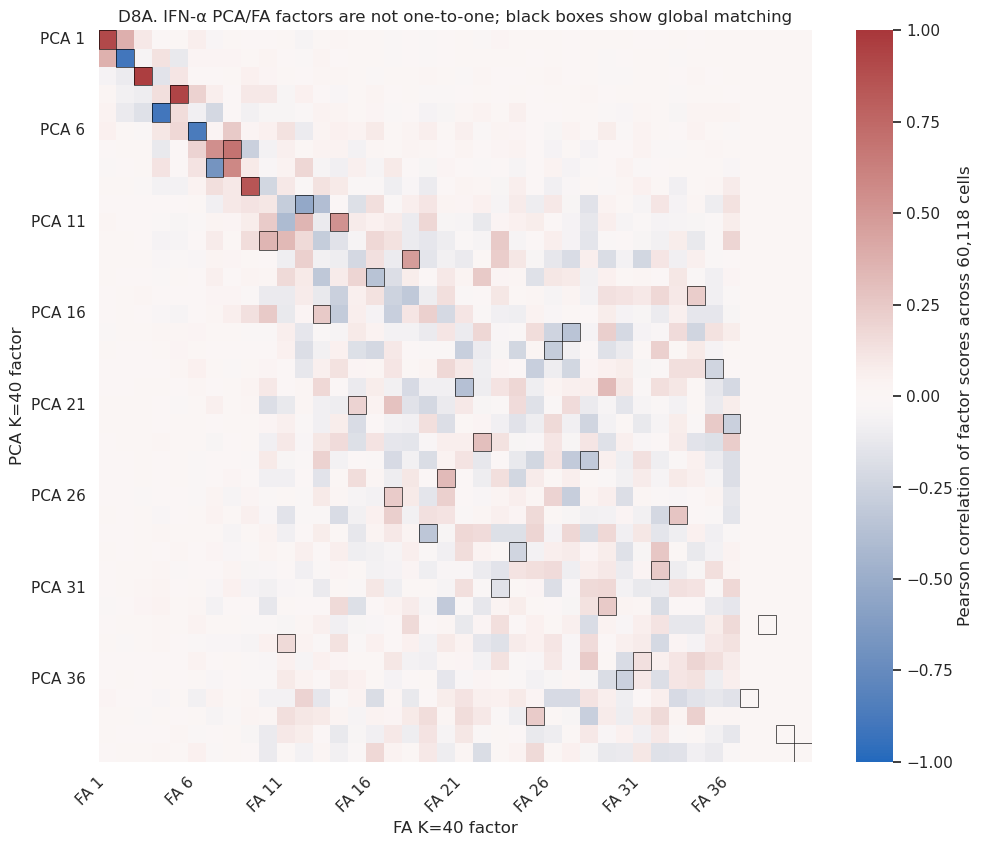

/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/meeting_followup_v1/D8B_interferon_alpha_active_factor_coefficients.png


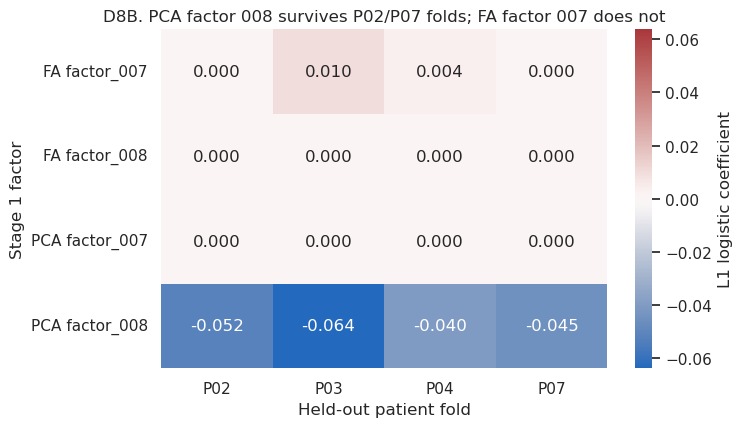

/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/meeting_followup_v1/D8C_interferon_alpha_driver_factor_ablation.png


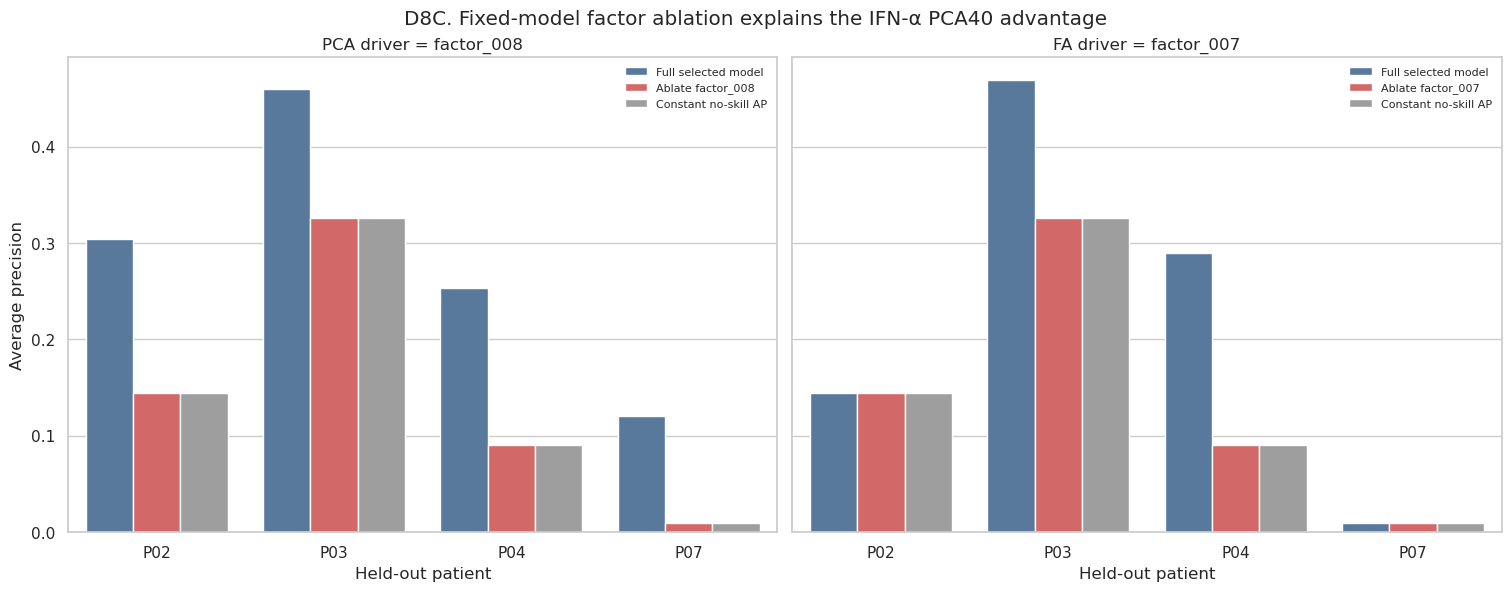

/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/meeting_followup_v1/D8D_interferon_alpha_driver_loading_genes.png


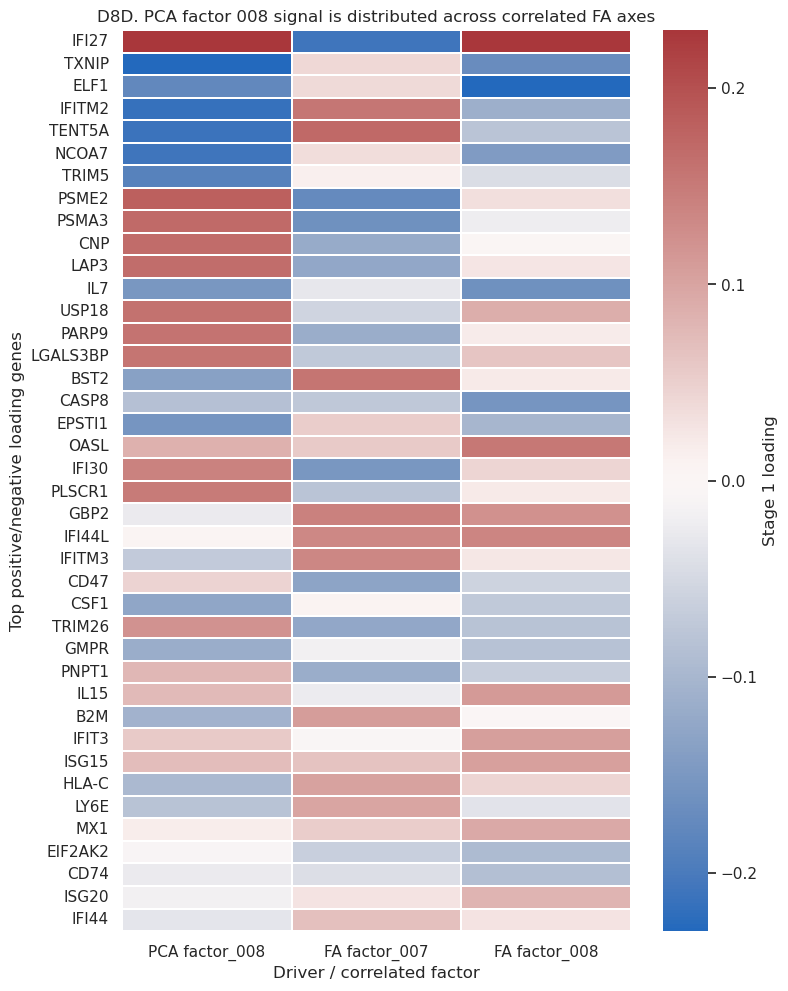

/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/meeting_followup_v1/D8E_interferon_alpha_pca_driver_correlations_to_fa.png


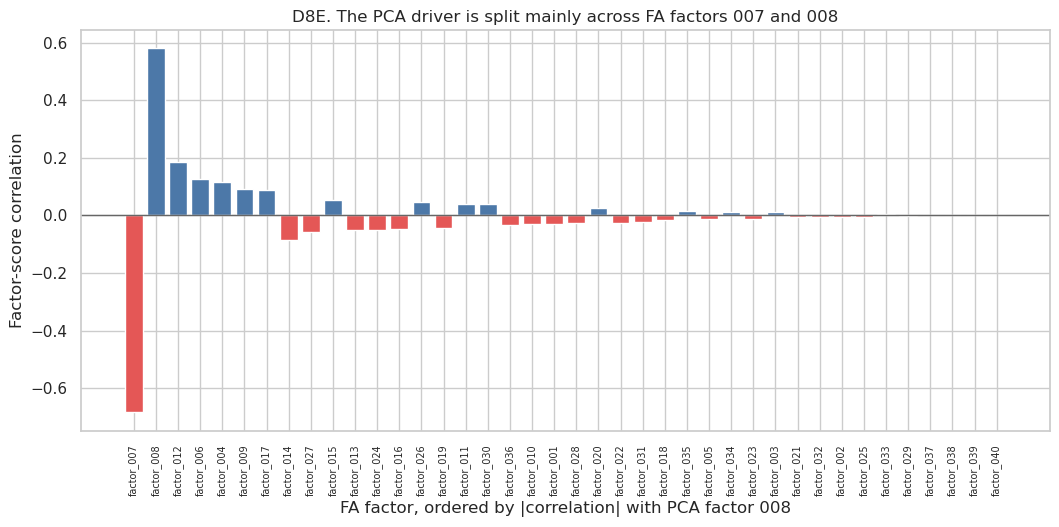

In [7]:
# D8A — full PCA/FA score-correlation alignment.
fig, ax = plt.subplots(figsize=(11.5, 9.5))
sns.heatmap(
    score_correlation,
    cmap="vlag",
    center=0,
    vmin=-1,
    vmax=1,
    cbar_kws={"label": "Pearson correlation of factor scores across 60,118 cells"},
    ax=ax,
)
for pca_index, fa_index in zip(pca_indices, fa_indices):
    ax.add_patch(plt.Rectangle((fa_index, pca_index), 1, 1, fill=False, edgecolor="black", lw=0.45))
ax.set_xticks(np.arange(0.5, 40.5, 5), [f"FA {index}" for index in range(1, 41, 5)], rotation=45, ha="right")
ax.set_yticks(np.arange(0.5, 40.5, 5), [f"PCA {index}" for index in range(1, 41, 5)], rotation=0)
ax.set_xlabel("FA K=40 factor")
ax.set_ylabel("PCA K=40 factor")
ax.set_title("D8A. IFN-α PCA/FA factors are not one-to-one; black boxes show global matching")
d8a_png = save_figure(fig, "D8A_interferon_alpha_pca_fa_factor_alignment")
plt.show()

# D8B — selected coefficients by held-out fold.
coefficient_features = sorted(active_coefficients["feature_id"].unique())
coefficient_rows = []
for method in ["pca", "fa"]:
    for feature_id in coefficient_features:
        for patient_id in FOCUS_PATIENTS:
            match = ifna_factor_ablation.loc[
                ifna_factor_ablation["stage1_method"].eq(method)
                & ifna_factor_ablation["feature_id"].eq(feature_id)
                & ifna_factor_ablation["heldout_patient"].eq(patient_id)
            ]
            coefficient_rows.append(
                {
                    "method_factor": f"{method.upper()} {feature_id}",
                    "heldout_patient": patient_id,
                    "coefficient": float(match["coefficient"].iloc[0]),
                }
            )
coefficient_matrix = pd.DataFrame(coefficient_rows).pivot(
    index="method_factor", columns="heldout_patient", values="coefficient"
).reindex(columns=FOCUS_PATIENTS)
coef_vmax = max(float(np.abs(coefficient_matrix.to_numpy()).max()), 1e-9)
fig, ax = plt.subplots(figsize=(7.2, 4.4))
sns.heatmap(
    coefficient_matrix,
    annot=True,
    fmt=".3f",
    cmap="vlag",
    center=0,
    vmin=-coef_vmax,
    vmax=coef_vmax,
    cbar_kws={"label": "L1 logistic coefficient"},
    ax=ax,
)
ax.set_xlabel("Held-out patient fold")
ax.set_ylabel("Stage 1 factor")
ax.set_title("D8B. PCA factor 008 survives P02/P07 folds; FA factor 007 does not")
d8b_png = save_figure(fig, "D8B_interferon_alpha_active_factor_coefficients")
plt.show()

# D8C — full versus driver-ablated AP.
method_driver = dict(zip(driver_by_method["stage1_method"], driver_by_method["feature_id"]))
d8c_records = []
for method in ["pca", "fa"]:
    driver_id = method_driver[method]
    for patient_id in FOCUS_PATIENTS:
        row = ifna_factor_ablation.loc[
            ifna_factor_ablation["stage1_method"].eq(method)
            & ifna_factor_ablation["feature_id"].eq(driver_id)
            & ifna_factor_ablation["heldout_patient"].eq(patient_id)
        ].iloc[0]
        for scenario, value in [
            ("Full selected model", row["full_model_ap"]),
            (f"Ablate {driver_id}", row["ablated_model_ap"]),
            ("Constant no-skill AP", row["patient_prevalence"]),
        ]:
            d8c_records.append(
                {
                    "stage1_method": method,
                    "heldout_patient": patient_id,
                    "scenario": scenario,
                    "average_precision": value,
                    "driver_feature_id": driver_id,
                }
            )
d8c = pd.DataFrame(d8c_records)
fig, axes = plt.subplots(1, 2, figsize=(15, 5.8), sharey=True, constrained_layout=True)
for ax, method in zip(axes, ["pca", "fa"]):
    subset = d8c.loc[d8c["stage1_method"].eq(method)]
    driver_id = method_driver[method]
    scenario_order = ["Full selected model", f"Ablate {driver_id}", "Constant no-skill AP"]
    sns.barplot(
        data=subset,
        x="heldout_patient",
        y="average_precision",
        hue="scenario",
        hue_order=scenario_order,
        palette=["#4C78A8", "#E45756", "#9E9E9E"],
        ax=ax,
    )
    ax.set_xlabel("Held-out patient")
    ax.set_ylabel("Average precision")
    ax.set_title(f"{method.upper()} driver = {driver_id}")
    ax.legend(frameon=False, fontsize=8)
fig.suptitle("D8C. Fixed-model factor ablation explains the IFN-α PCA40 advantage")
d8c_png = save_figure(fig, "D8C_interferon_alpha_driver_factor_ablation")
plt.show()

# D8D — top loading genes for the PCA driver and two correlated FA factors.
driver_loading_matrix = {}
for method, feature_id in driver_factor_specs:
    factor_index = int(feature_id.split("_")[1]) - 1
    driver_loading_matrix[f"{method.upper()} {feature_id}"] = pd.Series(
        loadings[method][:, factor_index], index=ifna_genes
    )
driver_loading_matrix = pd.DataFrame(driver_loading_matrix)
top_gene_union = set()
for column in driver_loading_matrix.columns:
    values = driver_loading_matrix[column]
    top_gene_union.update(values.nlargest(10).index)
    top_gene_union.update(values.nsmallest(10).index)
driver_loading_heatmap = driver_loading_matrix.loc[list(top_gene_union)].copy()
driver_loading_heatmap = driver_loading_heatmap.loc[
    driver_loading_heatmap.abs().max(axis=1).sort_values(ascending=False).index
]
loading_vmax = max(float(np.nanpercentile(np.abs(driver_loading_heatmap.to_numpy()), 98)), 1e-9)
fig, ax = plt.subplots(figsize=(8.2, max(7.0, 0.23 * len(driver_loading_heatmap) + 2.5)))
sns.heatmap(
    driver_loading_heatmap,
    cmap="vlag",
    center=0,
    vmin=-loading_vmax,
    vmax=loading_vmax,
    linewidths=0.25,
    linecolor="white",
    cbar_kws={"label": "Stage 1 loading"},
    ax=ax,
)
ax.set_xlabel("Driver / correlated factor")
ax.set_ylabel("Top positive/negative loading genes")
ax.set_title("D8D. PCA factor 008 signal is distributed across correlated FA axes")
d8d_png = save_figure(fig, "D8D_interferon_alpha_driver_loading_genes")
plt.show()

# D8E — PCA driver correlation across all FA factors.
d8e = fa_correlations_to_pca_driver.sort_values("absolute_score_correlation_to_pca_driver", ascending=False).copy()
fig, ax = plt.subplots(figsize=(12.5, 5.2))
colors = np.where(d8e["score_correlation_to_pca_driver"] >= 0, "#4C78A8", "#E45756")
ax.bar(d8e["fa_feature_id"], d8e["score_correlation_to_pca_driver"], color=colors)
ax.axhline(0, color="0.4", lw=1)
ax.set_xticks(np.arange(len(d8e)), d8e["fa_feature_id"], rotation=90, fontsize=7)
ax.set_xlabel("FA factor, ordered by |correlation| with PCA factor 008")
ax.set_ylabel("Factor-score correlation")
ax.set_title("D8E. The PCA driver is split mainly across FA factors 007 and 008")
d8e_png = save_figure(fig, "D8E_interferon_alpha_pca_driver_correlations_to_fa")
plt.show()

## 5. Presentation handoff and decision boundaries

This notebook resolves the metric-definition question and maps the completed DR interactions. The initial audit showed that only three panels had direct-gene rows because the original runner treated direct genes as a small-panel fallback. Section 6 records the completed 41-panel direct-gene follow-up run and its Stage 1 value-added comparison.

A donor-downsampling experiment is a separate sensitivity run. Downsampling only after global DR cannot change factor loadings; a valid design must distinguish fixed-basis Stage 2 training sensitivity from pre-DR basis sensitivity.

In [8]:
metric_association_summary = (
    metric_prevalence_association.groupby(["metric", "covariate"], as_index=False)
    .agg(
        median_spearman_rho=("spearman_rho_across_7_patients", "median"),
        p20_spearman_rho=("spearman_rho_across_7_patients", lambda values: values.quantile(0.20)),
        p80_spearman_rho=("spearman_rho_across_7_patients", lambda values: values.quantile(0.80)),
        n_representations=("representation_id", "nunique"),
    )
)
metric_association_summary_path = write_csv(
    metric_association_summary,
    "old34_metric_prevalence_association_summary.csv",
)


def plot_contract(
    plot_id: str,
    title: str,
    question: str,
    experiment: str,
    unit: str,
    metric: str,
    take_home: str,
    gaps: str,
) -> dict[str, str]:
    return {
        "plot_id": plot_id,
        "title": title,
        "scientific_question": question,
        "null_hypothesis": "No structured difference beyond the stated no-skill/reference comparison.",
        "in_silico_experiment": experiment,
        "unit_of_analysis": unit,
        "metric_and_baseline": metric,
        "take_home_message": take_home,
        "unresolved_gaps": gaps,
    }


plot_contracts = pd.DataFrame(
    [
        plot_contract("D6A", "MRD cell composition", "What malignant, donor-healthy, and recipient-healthy support exists per patient?", "Apply the exact CITE/MRD/binary-label filters to source AnnData and count patient × label × source.", "patient cell", "cell count; log and linear views", "Healthy comparators are overwhelmingly donor-derived, with a small recipient-healthy remainder.", "Source labels are observational and do not prove absence of donor-associated expression shifts."),
        plot_contract("D6B", "Held-out AP versus constant no-skill AP", "Are patient AP differences above the mathematically matched no-skill baseline?", "Plot 643 fixed-global-regularization AP values per patient and overlay constant-score AP.", "representation × held-out patient", "average precision; baseline = malignant prevalence", "Prevalence is the exact constant-score AP baseline, so raw lift is an AP-scale difference.", "AP uncertainty requires cell-level bootstrap/permutation analysis."),
        plot_contract("D6C", "Raw and normalized lift", "Does ceiling normalization materially change patient patterns?", "Compare AP−prevalence with (AP−prevalence)/(1−prevalence) for all 4,501 evaluations.", "representation × held-out patient", "raw and normalized AP lift; zero = no skill", "Normalized lift removes the prevalence-dependent upper ceiling but not sampling uncertainty.", "Only seven supported patients; no inferential patient ranking."),
        plot_contract("D6D", "Metric association with prevalence and counts", "How strongly do AP, lift, normalized lift, and AUROC track patient composition?", "Compute Spearman correlation across seven patients separately within every representation.", "representation", "Spearman rho; zero = no monotonic association", "Subtracting prevalence addresses the no-skill level; residual associations can still reflect biology, sampling, or selection weighting.", "Prevalence and malignant count are confounded in n=7."),
        plot_contract("D6E", "Dummy hard-policy utility", "Do majority/minority guesses define different AP baselines?", "Compute constant-score AP and hard-decision accuracy/sensitivity/specificity for both policies.", "patient × policy", "AP plus threshold utility metrics", "Both constant scores have AP=prevalence; utility choice belongs in threshold/cost metrics.", "Clinical cost ratios are not yet specified."),
        plot_contract("D7A", "PCA40 minus FA40 lift", "Where is PCA versus FA performance patient-specific?", "Subtract FA40 lift from PCA40 lift within every panel and patient.", "panel × held-out patient", "AUPRC lift difference in percentage points", "The IFN-alpha P02/P07 contrast is one member of a broader interaction map.", "No uncertainty bars or second Stage 1 seed."),
        plot_contract("D7B", "K40 method interaction range", "Which panel/patient pairs are most sensitive to DR method?", "Take max−min lift across four K=40 DR methods.", "panel × held-out patient", "AUPRC lift range in percentage points", "Large ranges nominate targeted factor review rather than a universal method winner.", "Range is selection-sensitive and descriptive."),
        plot_contract("D7C", "IFN-alpha method-by-K trajectories", "How does the IFN-alpha interaction evolve with K?", "Plot per-patient lift across four methods and K=5/10/20/40.", "representation × held-out patient", "AUPRC lift in percentage points; zero = no skill", "The PCA/FA divergence is K- and patient-dependent.", "One Stage 1 seed and globally selected regularization."),
        plot_contract("D7D", "IFN-alpha PCA40 versus FA40", "Which patients produce the concrete PCA40 advantage?", "Compare PCA40 and FA40 lift bars for all supported patients.", "held-out patient × method", "AUPRC lift in percentage points", "P02 and P07 drive the striking PCA advantage; P03/P04 are comparable or FA-favored.", "No confidence interval for AP differences."),
        plot_contract("D7E", "Direct-gene baseline coverage", "Is the no-DR comparator already complete?", "Audit observed direct_gene representation IDs across 41 panels.", "panel", "completed versus missing direct baseline", "Only three small-panel fallback baselines exist; stress arrest, p53, and IFN-alpha are missing.", "Completing this requires new direct-feature Stage 2 runs."),
        plot_contract("D7F", "MHC-I method-by-K trajectories", "Is the D7B MHC-I spread a K=40-only PCA collapse or a broader method trajectory?", "Plot per-patient lift across four methods and K=5/10/20/40 for MHC class I antigen presentation.", "representation × held-out patient", "AUPRC lift in percentage points; zero = no skill", "FA retains large P02/P03/P04 lift as K grows; PCA stays near zero for P02.", "One Stage 1 seed and globally selected regularization."),
        plot_contract("D7G", "EMT method-by-K trajectories", "Which methods produce the EMT D7B hotspot, and at which K?", "Plot per-patient lift across four methods and K=5/10/20/40 for epithelial mesenchymal transition.", "representation × held-out patient", "AUPRC lift in percentage points; zero = no skill", "P02 FactoSig/promax pull away at larger K; P03 is FA/FactoSig-high and promax-poor.", "One Stage 1 seed and globally selected regularization."),
        plot_contract("D7H", "IFN-gamma signaling method-by-K trajectories", "Does IFN-gamma signaling follow the IFN-alpha PCA/FA split?", "Plot per-patient lift across four methods and K=5/10/20/40 for Reactome interferon gamma signaling.", "representation × held-out patient", "AUPRC lift in percentage points; zero = no skill", "P02/P03 lift is FactoSig/promax-driven; FA stays at or below the no-skill line.", "Hallmark IFN-gamma response is a different panel and is not plotted here."),
        plot_contract("D7J", "D7B Stage 2 penalty and sparsity", "Does D7B compare Stage 1 methods at a fixed L1 or L2, or at best transfer?", "Show the pooled-LOPO-selected penalty family and median nonzero LOPO coefficients for every K=40 DR representation.", "panel × Stage 1 method", "selected penalty; median nonzero coefficients out of K=40", "D7B freezes one global regularizer per representation; L1/EN often leave PCA/FA with 0–2 active factors.", "Sparsity is fold-specific; coefficient identity is not shown."),
        plot_contract("D7K", "D7B method-spread under Stage 2 policies", "Does the D7B hotspot survive if Stage 2 is restricted to L1, L2, or patient-wise best transfer?", "Rebuild max−min K=40 method lift after selecting best L1, best L2, or the per-patient best regularization.", "panel × held-out patient × Stage 2 policy", "AUPRC lift range in percentage points", "L2 and patient-oracle shrink the MHC-I/EMT/IFN-γ hotspots; selected mixed and L1 preserve them.", "Best-L1/L2 still use one global C per representation; oracle is not a deployable selector."),
        plot_contract("D7L", "Hotspot K=40 lifts under L1 vs L2", "For D7B hotspot panels, is method rank an L1-sparsity artifact?", "Compare K=40 patient lifts under the selected mixed regularizer, best L1, and best L2.", "held-out patient × method × Stage 2 policy", "AUPRC lift in percentage points", "Under L2, PCA and FA recover P02 lift and the four methods converge; selected/L1 keep sparse winners and zeroed losers.", "One Stage 1 seed; C is still chosen by pooled LOPO within each penalty family."),
        plot_contract("D8A", "PCA/FA factor alignment", "Do PCA and FA recover one-to-one IFN-alpha factors?", "Correlate all PCA40 and FA40 score vectors and solve maximum-|correlation| matching.", "PCA factor × FA factor", "factor-score Pearson correlation", "The bases are not one-to-one and four FA factors are degenerate in score variance.", "Alignment is transductive and single-seed."),
        plot_contract("D8B", "Active IFN-alpha coefficients", "Which factor survives L1 selection in each held-out fold?", "Display selected L1 coefficients at the identical global regularization.", "factor × held-out-patient fold", "standardized logistic coefficient; zero = excluded", "PCA factor 008 survives P02/P07; FA factor 007 is zero in those folds.", "Coefficient stability is conditional on the fixed regularization."),
        plot_contract("D8C", "IFN-alpha driver ablation", "Does the selected driver account for the held-out AP gain?", "Reconstruct linear rankings and remove one factor contribution without refitting.", "held-out patient × method", "average precision; constant-score baseline = prevalence", "Removing PCA factor 008 collapses its one-factor selected models to baseline.", "Fixed-model ablation does not estimate a refitted replacement model."),
        plot_contract("D8D", "IFN-alpha driver genes", "Which genes define the PCA driver and correlated FA axes?", "Extract top positive/negative Stage 1 loadings for PCA driver and two most correlated FA factors.", "gene × factor", "signed Stage 1 loading", "PCA factor 008 spans an IFI27/proteasome versus TXNIP/IFITM axis split across FA factors.", "Gene loadings are hypotheses, not causal biomarkers."),
        plot_contract("D8E", "PCA driver correlations to FA", "Is the PCA driver concentrated in one FA factor?", "Rank all FA factor-score correlations with PCA factor 008.", "FA factor", "Pearson correlation with PCA factor 008", "The PCA driver is distributed mainly across FA factors 007 and 008.", "Correlation does not prove why L1 selects one basis more reliably."),
    ]
)
plot_contracts_path = write_csv(plot_contracts, "meeting_followup_plot_contracts.csv")

association_lookup = metric_association_summary.set_index(["metric", "covariate"])["median_spearman_rho"]
fa_degenerate = [f"factor_{index + 1:03d}" for index, valid in enumerate(fa_nondegenerate) if not valid]
report_lines = [
    "# Old34 meeting follow-up findings",
    "",
    f"Generated: {datetime.now(timezone.utc).isoformat()}",
    "",
    "## Metric validity",
    "",
    "- Stage 2 uses `sklearn.metrics.average_precision_score`.",
    "- Constant all-healthy and all-malignant scores both reproduce malignant prevalence exactly as AP.",
    "- Hard policies differ in sensitivity/specificity/accuracy, not AP ranking baseline.",
    "- Retain raw lift `AP - prevalence`; add normalized lift `(AP - prevalence)/(1 - prevalence)`.",
    f"- Median within-representation rho(AP, prevalence): {association_lookup[('heldout_auprc', 'patient_prevalence')]:.3f}.",
    f"- Median within-representation rho(raw lift, prevalence): {association_lookup[('heldout_lift', 'patient_prevalence')]:.3f}.",
    f"- Median within-representation rho(normalized lift, prevalence): {association_lookup[('normalized_heldout_lift', 'patient_prevalence')]:.3f}.",
    "",
    "## Donor/recipient transparency",
    "",
    f"- Exact filtered MRD/CITE binary cohort: {len(mrd_obs):,} cells.",
    f"- Recipient-healthy counts across patients: {dict(zip(patient_composition['patient_id'], patient_composition['n_healthy_recipient']))}.",
    "- Donor healthy cells are the practical comparator, but donor sensitivity remains a required targeted rerun.",
    "",
    "## IFN-alpha PCA40 versus FA40",
    "",
    f"- Maximum AP reconstruction error from stored scores/coefficients: {ifna_reconstruction['absolute_reconstruction_error'].max():.2e}.",
    f"- PCA driver: {pca_driver_id}; it is the only active PCA factor in the focus folds.",
    f"- Most correlated FA factors: {', '.join(fa_driver_candidates['fa_feature_id'])}.",
    f"- Degenerate FA score factors: {', '.join(fa_degenerate)}.",
    "- PCA factor 008 remains selected in P02/P03/P04/P07; FA factor 007 remains selected only in P03/P04.",
    "",
    "## D7B hotspot method-by-K trajectories",
    "",
    "- MHC-I, EMT, and IFN-gamma signaling are the largest K=40 max−min method spreads.",
    "- MHC-I P02 is FA-high and PCA-near-zero; EMT P02 is FactoSig/promax-high; IFN-gamma signaling P02/P03 are FactoSig/promax-high with FA at or below baseline.",
    "- D7B does not fix L1 or L2. Each representation uses one globally selected pooled-LOPO regularizer, which may be L1, L2, or elastic net.",
    "- Those D7B hotspots largely disappear under L2: PCA/FA recover dense models, so method spread is a Stage 2 sparsity effect as much as a Stage 1 ranking.",
    "",
    "## No-DR baseline gap",
    "",
    f"- Completed direct-gene baselines: {len(direct_ids)}/41 panels.",
    "- Stress arrest, p53, and IFN-alpha direct-gene baselines are not present and require new Stage 2 runs.",
]
report_path = TABLE_DIR / "meeting_followup_findings.md"
report_path.write_text("\n".join(report_lines) + "\n")

manifest = {
    "created_utc": datetime.now(timezone.utc).isoformat(),
    "experiment_id": EXPERIMENT_ID,
    "suite_version": "old34_meeting_followup_v1",
    "model_reruns": False,
    "counts": {
        "mrd_binary_cells": len(mrd_obs),
        "representations": patient_metrics["representation_id"].nunique(),
        "supported_patient_representation_rows": len(patient_metrics),
        "direct_gene_panels_completed": len(direct_ids),
        "ifna_factor_ablation_rows": len(ifna_factor_ablation),
        "plot_contracts": len(plot_contracts),
    },
    "source_files": {name: source_signature(path) for name, path in SOURCE_PATHS.items()},
    "metric_definition": {
        "implementation": "sklearn.metrics.average_precision_score",
        "constant_score_no_skill_ap": "malignant prevalence",
        "raw_lift": "AP - prevalence",
        "normalized_lift": "(AP - prevalence) / (1 - prevalence)",
    },
}
manifest_path = TABLE_DIR / "meeting_followup_manifest.json"
manifest_path.write_text(json.dumps(manifest, indent=2) + "\n")

ledger_path = TABLE_DIR / "meeting_followup_artifact_ledger.csv"
validation_path = TABLE_DIR / "meeting_followup_validation.json"
artifact_paths = sorted(
    path
    for root in [TABLE_DIR, FIGURE_DIR]
    for path in root.rglob("*")
    if path.is_file() and path not in {ledger_path, validation_path}
)
ledger_records = []
for path in artifact_paths:
    if path.suffix.lower() == ".csv":
        artifact_type = "table"
        n_rows = len(pd.read_csv(path, low_memory=False))
    elif path.suffix.lower() in {".png", ".pdf"}:
        artifact_type = "figure"
        n_rows = np.nan
    elif path.suffix.lower() == ".md":
        artifact_type = "report"
        n_rows = np.nan
    else:
        artifact_type = "manifest"
        n_rows = np.nan
    ledger_records.append(
        {
            "artifact_id": path.stem,
            "artifact_type": artifact_type,
            "relative_path": str(path.relative_to(EXP_DIR)),
            "size_bytes": path.stat().st_size,
            "sha256": sha256_file(path),
            "n_rows_if_csv": n_rows,
            "modified_utc": datetime.fromtimestamp(path.stat().st_mtime, timezone.utc).isoformat(),
        }
    )
artifact_ledger = pd.DataFrame(ledger_records).sort_values(["artifact_type", "relative_path"]).reset_index(drop=True)
artifact_ledger.to_csv(ledger_path, index=False)

assert len(patient_metrics) == 4_501
assert len(patient_composition) == 13
assert patient_composition["supported_for_lift_summary"].sum() == 7
assert dummy_policy_metrics.groupby("patient_id")["constant_score_average_precision"].nunique().eq(1).all()
assert pca_fa_wide["stage0_panel_id"].nunique() == k40["stage0_panel_id"].nunique()
assert method_spread["stage0_panel_id"].nunique() == k40["stage0_panel_id"].nunique()
assert pca_fa_wide["stage0_panel_id"].nunique() >= 35
assert len(ifna_pca_fa40) == 14
assert len(mhci_patient) == 112
assert len(emt_patient) == 112
assert len(ifng_patient) == 112
assert len(k40_rep) == 152
assert ifna_reconstruction["absolute_reconstruction_error"].max() < 2e-5
assert set(fa_degenerate) == {"factor_037", "factor_038", "factor_039", "factor_040"}
assert len(direct_ids) == 3
assert len(GENERATED_FIGURES) == 42
for path in artifact_paths + [ledger_path]:
    assert path.exists() and path.stat().st_size > 0

disk = shutil.disk_usage(EXP_DIR)
validation = {
    "validated_utc": datetime.now(timezone.utc).isoformat(),
    "status": "pass",
    "model_reruns": False,
    "mrd_binary_cells": len(mrd_obs),
    "patient_metric_rows": len(patient_metrics),
    "representation_count": patient_metrics["representation_id"].nunique(),
    "supported_patients": len(SUPPORTED_PATIENTS),
    "direct_gene_panels_completed": len(direct_ids),
    "ifna_max_ap_reconstruction_error": float(ifna_reconstruction["absolute_reconstruction_error"].max()),
    "plot_contract_rows": len(plot_contracts),
    "tracked_artifacts_excluding_ledger_and_validation": len(artifact_ledger),
    "tracked_bytes_excluding_ledger_and_validation": int(artifact_ledger["size_bytes"].sum()),
    "filesystem_free_gib": disk.free / 1024**3,
}
validation_path.write_text(json.dumps(validation, indent=2) + "\n")

print("Validation: PASS")
print("Tracked artifacts including ledger and validation:", len(artifact_ledger) + 2)
print("Presentation report:", report_path)
display(metric_association_summary)
display(ifna_reconstruction)

Validation: PASS
Tracked artifacts including ledger and validation: 76
Presentation report: /home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/scorecards/stage2_diagnostic/meeting_followup_v1/meeting_followup_findings.md


,metric,covariate,median_spearman_rho,p20_spearman_rho,p80_spearman_rho,n_representations
0,heldout_auprc,n_malignant_h,0.750000,0.607143,0.785714,643
1,heldout_auprc,n_normal_h,-0.642857,-0.678571,-0.607143,643
2,heldout_auprc,patient_prevalence,0.964286,0.892857,1.000000,643
3,heldout_auroc,n_malignant_h,0.571429,0.285714,0.785714,643
4,heldout_auroc,n_normal_h,-0.214286,-0.571429,0.107143,643
5,heldout_auroc,patient_prevalence,0.500000,0.107143,0.714286,643
6,heldout_lift,n_malignant_h,0.607143,0.300000,0.785714,643
7,heldout_lift,n_normal_h,-0.571429,-0.735714,-0.142857,643
8,heldout_lift,patient_prevalence,0.821429,0.321429,0.857143,643
9,normalized_heldout_lift,n_malignant_h,0.678571,0.535714,0.821429,643


,stage1_method,heldout_patient,representation_id,expected_heldout_ap,reconstructed_heldout_ap,absolute_reconstruction_error,active_factor_count,patient_prevalence
0,pca,P01,single_geneset__hallmark_interferon_alpha_response|dr|pca|40|42,0.003794,0.003794,4.770490e-17,0,0.003794
1,pca,P02,single_geneset__hallmark_interferon_alpha_response|dr|pca|40|42,0.303741,0.303741,0.000000e+00,1,0.144323
2,pca,P03,single_geneset__hallmark_interferon_alpha_response|dr|pca|40|42,0.459714,0.459715,5.897555e-07,1,0.325741
3,pca,P04,single_geneset__hallmark_interferon_alpha_response|dr|pca|40|42,0.253098,0.253098,1.110223e-16,1,0.090426
4,pca,P06,single_geneset__hallmark_interferon_alpha_response|dr|pca|40|42,0.014122,0.014122,2.602085e-17,1,0.013501
5,pca,P07,single_geneset__hallmark_interferon_alpha_response|dr|pca|40|42,0.120820,0.120820,2.775558e-17,1,0.010069
6,pca,P09,single_geneset__hallmark_interferon_alpha_response|dr|pca|40|42,0.021897,0.021897,4.163336e-17,0,0.021897
7,fa,P01,single_geneset__hallmark_interferon_alpha_response|dr|fa|40|42,0.003794,0.003794,4.770490e-17,0,0.003794
8,fa,P02,single_geneset__hallmark_interferon_alpha_response|dr|fa|40|42,0.144323,0.144323,5.551115e-17,0,0.144323
9,fa,P03,single_geneset__hallmark_interferon_alpha_response|dr|fa|40|42,0.469402,0.469400,1.384502e-06,1,0.325741


## 6. D9 — completed no-DR direct-gene baselines

The follow-up run materialized direct standardized gene matrices for all 41 panels and fit the same 65-setting regularization grid for discovery and LOPO. No patient-specific models were run.

For each direct representation, one global regularization is selected by pooled-cell LOPO AP using the same nonzero/tie-breaking policy as the DR diagnostic suite. It is then evaluated per patient without reselecting regularization. “Best DR” is selected per panel by pooled-cell LOPO AP—not by the held-out patient's result—before patient-level comparisons.

In [9]:
import sys

STAGE2_SCRIPT_DIR = REPO_ROOT / "scripts" / "mrd_stage0_2" / "stage2_supervised"
if str(STAGE2_SCRIPT_DIR) not in sys.path:
    sys.path.insert(0, str(STAGE2_SCRIPT_DIR))
from stage2_sharedness_plotting import select_regularization_rows

DIRECT_BRANCH = "old34_direct_gene_all_v1"
DIRECT_RUN_ID = "20260724_old34_direct_gene_all_v1_gpu8"
DIRECT_PATHS = {
    "direct_stage0_scorecard": EXP_DIR / "analysis" / "scorecards" / DIRECT_BRANCH / "stage0_mrd_old34_broad_scorecard.csv",
    "direct_discovery_scorecard": EXP_DIR / "analysis" / "scorecards" / DIRECT_BRANCH / "stage2_discovery_full_cohort_scorecard.csv",
    "direct_lopo_scorecard": EXP_DIR / "analysis" / "scorecards" / DIRECT_BRANCH / "stage2_sharedness_lopo_scorecard.csv",
    "direct_lopo_by_patient": EXP_DIR / "stage2_supervised" / "multiobjective" / DIRECT_BRANCH / "sharedness_lopo" / "by_heldout_patient.csv",
    "direct_launcher_manifest": EXP_DIR / "stage2_supervised" / "multiobjective" / DIRECT_BRANCH / "runs" / DIRECT_RUN_ID / "launcher_manifest.json",
}
for name, path in DIRECT_PATHS.items():
    if not path.exists():
        raise FileNotFoundError(f"Missing {name}: {path}")
SOURCE_PATHS.update(DIRECT_PATHS)

direct_stage0 = pd.read_csv(DIRECT_PATHS["direct_stage0_scorecard"], low_memory=False)
direct_lopo = pd.read_csv(DIRECT_PATHS["direct_lopo_scorecard"], low_memory=False)
direct_lopo_patient = pd.read_csv(DIRECT_PATHS["direct_lopo_by_patient"], low_memory=False)
assert len(direct_stage0) == 41 and direct_stage0["stage2_status"].eq("ok").all()
assert len(direct_lopo) == 41 * 65
assert len(direct_lopo_patient) == 41 * 65 * 13

direct_lopo["representation_id"] = (
    direct_lopo["stage0_panel_id"].astype(str)
    + "|direct_gene|direct_gene|"
    + pd.to_numeric(direct_lopo["effective_k"], errors="coerce").round().astype("Int64").astype(str)
    + "|"
    + pd.to_numeric(direct_lopo["seed"], errors="coerce").round().astype("Int64").astype(str)
)
direct_selected = select_regularization_rows(
    direct_lopo,
    group_cols=["representation_id"],
    metric_col="cell_weighted_auprc",
    mode="max_metric",
    penalty_priority=("elasticnet", "l1", "l2"),
    min_nonzero=1,
)
assert len(direct_selected) == 41

def regularization_keys(frame: pd.DataFrame) -> pd.DataFrame:
    out = frame.copy()
    out["penalty_key"] = out["penalty"].astype(str).str.lower()
    out["C_key"] = pd.to_numeric(out["C"], errors="coerce").round(12)
    out["l1_ratio_key"] = pd.to_numeric(out["l1_ratio"], errors="coerce").fillna(-1.0).round(12)
    return out


direct_selected = regularization_keys(direct_selected)
direct_lopo_patient = regularization_keys(direct_lopo_patient)
direct_patient_selected = direct_lopo_patient.merge(
    direct_selected[["stage0_panel_id", "penalty_key", "C_key", "l1_ratio_key", "representation_id", "selected_metric_value"]],
    on=["stage0_panel_id", "penalty_key", "C_key", "l1_ratio_key"],
    how="inner",
    validate="many_to_one",
)
direct_patient_selected = direct_patient_selected.loc[
    direct_patient_selected["heldout_patient"].isin(SUPPORTED_PATIENTS)
].copy()
direct_patient_selected["patient_prevalence"] = (
    direct_patient_selected["n_malignant"]
    / (direct_patient_selected["n_malignant"] + direct_patient_selected["n_normal"])
)
direct_patient_selected["heldout_lift"] = (
    direct_patient_selected["stage2_auprc"] - direct_patient_selected["patient_prevalence"]
)
direct_patient_selected["normalized_heldout_lift"] = (
    direct_patient_selected["heldout_lift"] / (1 - direct_patient_selected["patient_prevalence"])
)
direct_patient_selected = direct_patient_selected.merge(
    panel_base,
    on=["stage0_panel_id", "n_covered_genes"],
    how="left",
    validate="many_to_one",
)
direct_patient_selected["panel_label_with_genes"] = (
    direct_patient_selected["short_panel_label"]
    + " ("
    + direct_patient_selected["n_covered_genes"].astype(int).astype(str)
    + ")"
)
direct_patient_selected_path = write_csv(
    direct_patient_selected,
    "old34_direct_gene_selected_patient_metrics.csv",
)

direct_summary = (
    direct_patient_selected.groupby(
        ["stage0_panel_id", "short_panel_label", "panel_label_with_genes", "n_covered_genes", "representation_id"],
        as_index=False,
    )
    .agg(
        direct_pooled_lopo_ap=("selected_metric_value", "first"),
        direct_median_heldout_ap=("stage2_auprc", "median"),
        direct_median_lift=("heldout_lift", "median"),
        direct_p20_lift=("heldout_lift", lambda values: values.quantile(0.20)),
        direct_median_normalized_lift=("normalized_heldout_lift", "median"),
        direct_p20_normalized_lift=("normalized_heldout_lift", lambda values: values.quantile(0.20)),
        direct_positive_lift_patients=("heldout_lift", lambda values: int((values > 0).sum())),
    )
)

best_dr = (
    representation.loc[representation["stage1_method"].ne("direct_gene")]
    .sort_values(
        ["stage0_panel_id", "lopo_auprc_pooled", "patient_p20_lift", "patient_median_lift"],
        ascending=[True, False, False, False],
    )
    .groupby("stage0_panel_id", as_index=False)
    .head(1)
    [[
        "stage0_panel_id",
        "representation_id",
        "stage1_method",
        "effective_k",
        "lopo_auprc_pooled",
        "patient_median_lift",
        "patient_p20_lift",
    ]]
    .rename(
        columns={
            "representation_id": "best_dr_representation_id",
            "stage1_method": "best_dr_method",
            "effective_k": "best_dr_k",
            "lopo_auprc_pooled": "best_dr_pooled_lopo_ap",
            "patient_median_lift": "best_dr_median_lift",
            "patient_p20_lift": "best_dr_p20_lift",
        }
    )
)
direct_vs_best_dr = direct_summary.merge(best_dr, on="stage0_panel_id", how="left", validate="one_to_one")
direct_vs_best_dr["dr_value_added_pooled_lopo_ap"] = (
    direct_vs_best_dr["best_dr_pooled_lopo_ap"] - direct_vs_best_dr["direct_pooled_lopo_ap"]
)
direct_vs_best_dr["dr_value_added_median_lift"] = (
    direct_vs_best_dr["best_dr_median_lift"] - direct_vs_best_dr["direct_median_lift"]
)
direct_vs_best_dr["dr_value_added_p20_lift"] = (
    direct_vs_best_dr["best_dr_p20_lift"] - direct_vs_best_dr["direct_p20_lift"]
)
direct_vs_best_dr_path = write_csv(
    direct_vs_best_dr,
    "old34_direct_gene_vs_best_dr_summary.csv",
)

best_dr_patient = patient_metrics.merge(
    best_dr[["stage0_panel_id", "best_dr_representation_id", "best_dr_method", "best_dr_k"]],
    left_on=["stage0_panel_id", "representation_id"],
    right_on=["stage0_panel_id", "best_dr_representation_id"],
    how="inner",
    validate="many_to_one",
)
direct_vs_best_dr_patient = direct_patient_selected.merge(
    best_dr_patient[["stage0_panel_id", "heldout_patient", "heldout_auprc", "heldout_lift", "normalized_heldout_lift", "best_dr_representation_id", "best_dr_method", "best_dr_k"]],
    on=["stage0_panel_id", "heldout_patient"],
    how="left",
    suffixes=("_direct", "_best_dr"),
    validate="one_to_one",
)
direct_vs_best_dr_patient["dr_value_added_patient_lift"] = (
    direct_vs_best_dr_patient["heldout_lift_best_dr"] - direct_vs_best_dr_patient["heldout_lift_direct"]
)
direct_vs_best_dr_patient_path = write_csv(
    direct_vs_best_dr_patient,
    "old34_direct_gene_vs_best_dr_by_patient.csv",
)

launcher_manifest = json.loads(DIRECT_PATHS["direct_launcher_manifest"].read_text())
assert launcher_manifest["status"] == "completed"
assert not launcher_manifest["outputs"]["failures"]
assert launcher_manifest["outputs"]["merge"]["lopo_rows"] == 41 * 65
print("Direct baseline run: 41/41 panels, discovery + LOPO, no shard failures")
display(direct_vs_best_dr.sort_values("dr_value_added_p20_lift", ascending=False).head(12))

Direct baseline run: 41/41 panels, discovery + LOPO, no shard failures


,stage0_panel_id,short_panel_label,panel_label_with_genes,n_covered_genes,representation_id,direct_pooled_lopo_ap,direct_median_heldout_ap,direct_median_lift,direct_p20_lift,direct_median_normalized_lift,direct_p20_normalized_lift,direct_positive_lift_patients,best_dr_representation_id,best_dr_method,best_dr_k,best_dr_pooled_lopo_ap,best_dr_median_lift,best_dr_p20_lift,dr_value_added_pooled_lopo_ap,dr_value_added_median_lift,dr_value_added_p20_lift
1,single_geneset__hallmark_apoptosis,apoptosis,apoptosis (138),138,single_geneset__hallmark_apoptosis|direct_gene|direct_gene|138|42,0.093457,0.021945,4.827592e-05,-5.394990e-17,4.935666e-05,-7.544064e-17,4,single_geneset__hallmark_apoptosis|dr|factosig_promax|40|42,factosig_promax,40,0.115498,1.152007e-01,2.475455e-02,0.022041,0.115152,0.024755
32,single_geneset__reactome_nf_kb_activation,nf kb activation,nf kb activation (12),12,single_geneset__reactome_nf_kb_activation|direct_gene|direct_gene|12|42,0.058217,0.021897,-3.672872e-03,-1.652129e-02,-3.710229e-03,-1.894280e-02,0,single_geneset__reactome_nf_kb_activation|dr|fa|5|42,fa,5,0.049145,-4.163336e-17,-5.394990e-17,-0.009072,0.003673,0.016521
0,single_geneset__hallmark_allograft_rejection,allograft rejection,allograft rejection (147),147,single_geneset__hallmark_allograft_rejection|direct_gene|direct_gene|147|42,0.111712,0.026174,2.288896e-03,5.765400e-04,2.297614e-03,5.834208e-04,6,single_geneset__hallmark_allograft_rejection|dr|pca|20|42,pca,20,0.191563,4.763799e-02,1.516509e-02,0.079851,0.045349,0.014589
40,single_group__tgf_plasticity,tgf plasticity,tgf plasticity (146),146,single_group__tgf_plasticity|direct_gene|direct_gene|146|42,0.081530,0.154982,7.368933e-02,1.984638e-02,8.101517e-02,2.438370e-02,7,single_group__tgf_plasticity|dr|factosig|40|42,factosig,40,0.095068,8.804423e-02,3.097907e-02,0.013539,0.014355,0.011133
11,single_geneset__hallmark_inflammatory_response,inflammatory response,inflammatory response (135),135,single_geneset__hallmark_inflammatory_response|direct_gene|direct_gene|135|42,0.163667,0.114342,1.042732e-01,2.691748e-02,1.053338e-01,2.736671e-02,7,single_geneset__hallmark_inflammatory_response|dr|factosig_promax|20|42,factosig_promax,20,0.350858,7.318455e-02,3.566777e-02,0.187191,-0.031089,0.008750
2,single_geneset__hallmark_complement,complement,complement (154),154,single_geneset__hallmark_complement|direct_gene|direct_gene|154|42,0.150244,0.024762,-4.163336e-17,-5.394990e-17,-4.256540e-17,-7.544064e-17,2,single_geneset__hallmark_complement|dr|pca|40|42,pca,40,0.151588,3.051855e-02,8.106333e-03,0.001344,0.030519,0.008106
25,single_geneset__kegg_toll_like_receptor_signaling_pathway,toll like receptor signaling pathway,toll like receptor signaling pathway (77),77,single_geneset__kegg_toll_like_receptor_signaling_pathway|direct_gene|direct_gene|77|42,0.079164,0.045406,3.417596e-02,7.505147e-03,3.452357e-02,7.648772e-03,7,single_geneset__kegg_toll_like_receptor_signaling_pathway|dr|fa|20|42,fa,20,0.101254,3.739992e-02,1.468570e-02,0.022090,0.003224,0.007181
9,single_geneset__hallmark_il2_stat5_signaling,il2 stat5 signaling,il2 stat5 signaling (164),164,single_geneset__hallmark_il2_stat5_signaling|direct_gene|direct_gene|164|42,0.113804,0.089810,6.791310e-02,1.041273e-02,6.943345e-02,1.047884e-02,7,single_geneset__hallmark_il2_stat5_signaling|dr|factosig|40|42,factosig,40,0.122208,7.896562e-02,1.653907e-02,0.008404,0.011053,0.006126
31,single_geneset__reactome_mhc_class_ii_antigen_presentation,mhc class ii antigen presentation,mhc class ii antigen presentation (105),105,single_geneset__reactome_mhc_class_ii_antigen_presentation|direct_gene|direct_gene|105|42,0.077940,0.033878,3.557401e-04,2.353859e-05,3.593584e-04,2.374870e-05,6,single_geneset__reactome_mhc_class_ii_antigen_presentation|dr|factosig|40|42,factosig,40,0.095960,2.969339e-02,5.473658e-03,0.018020,0.029338,0.005450
26,single_geneset__reactome_antigen_presentation_folding_assembly_and_peptide_loading_of_class_i_mhc,antigen presentation folding

/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/meeting_followup_v1/D9A_direct_gene_vs_best_dr_pooled_lopo_ap.png


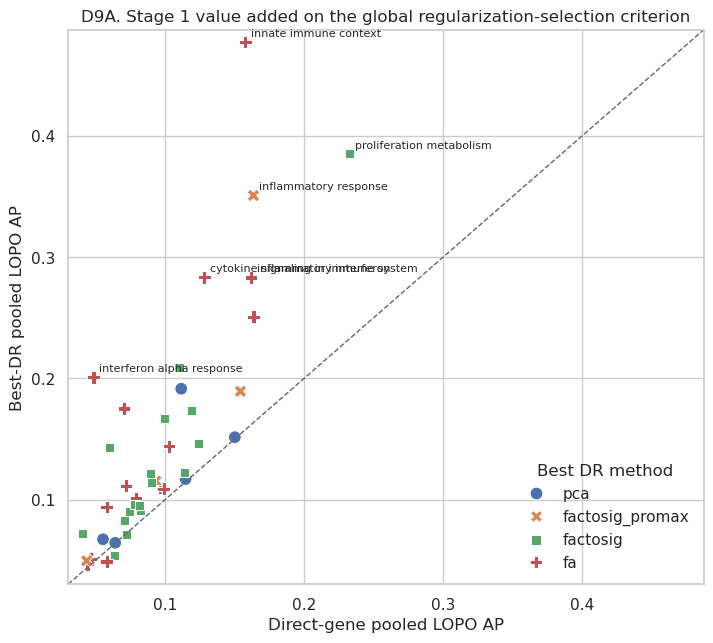

/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/meeting_followup_v1/D9B_direct_gene_vs_best_dr_p20_lift.png


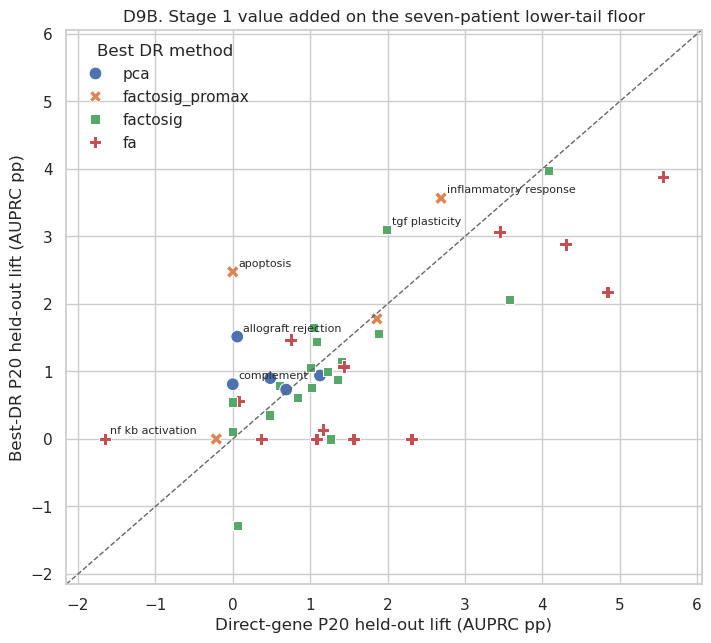

/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/meeting_followup_v1/D9C_best_dr_minus_direct_gene_patient_lift.png


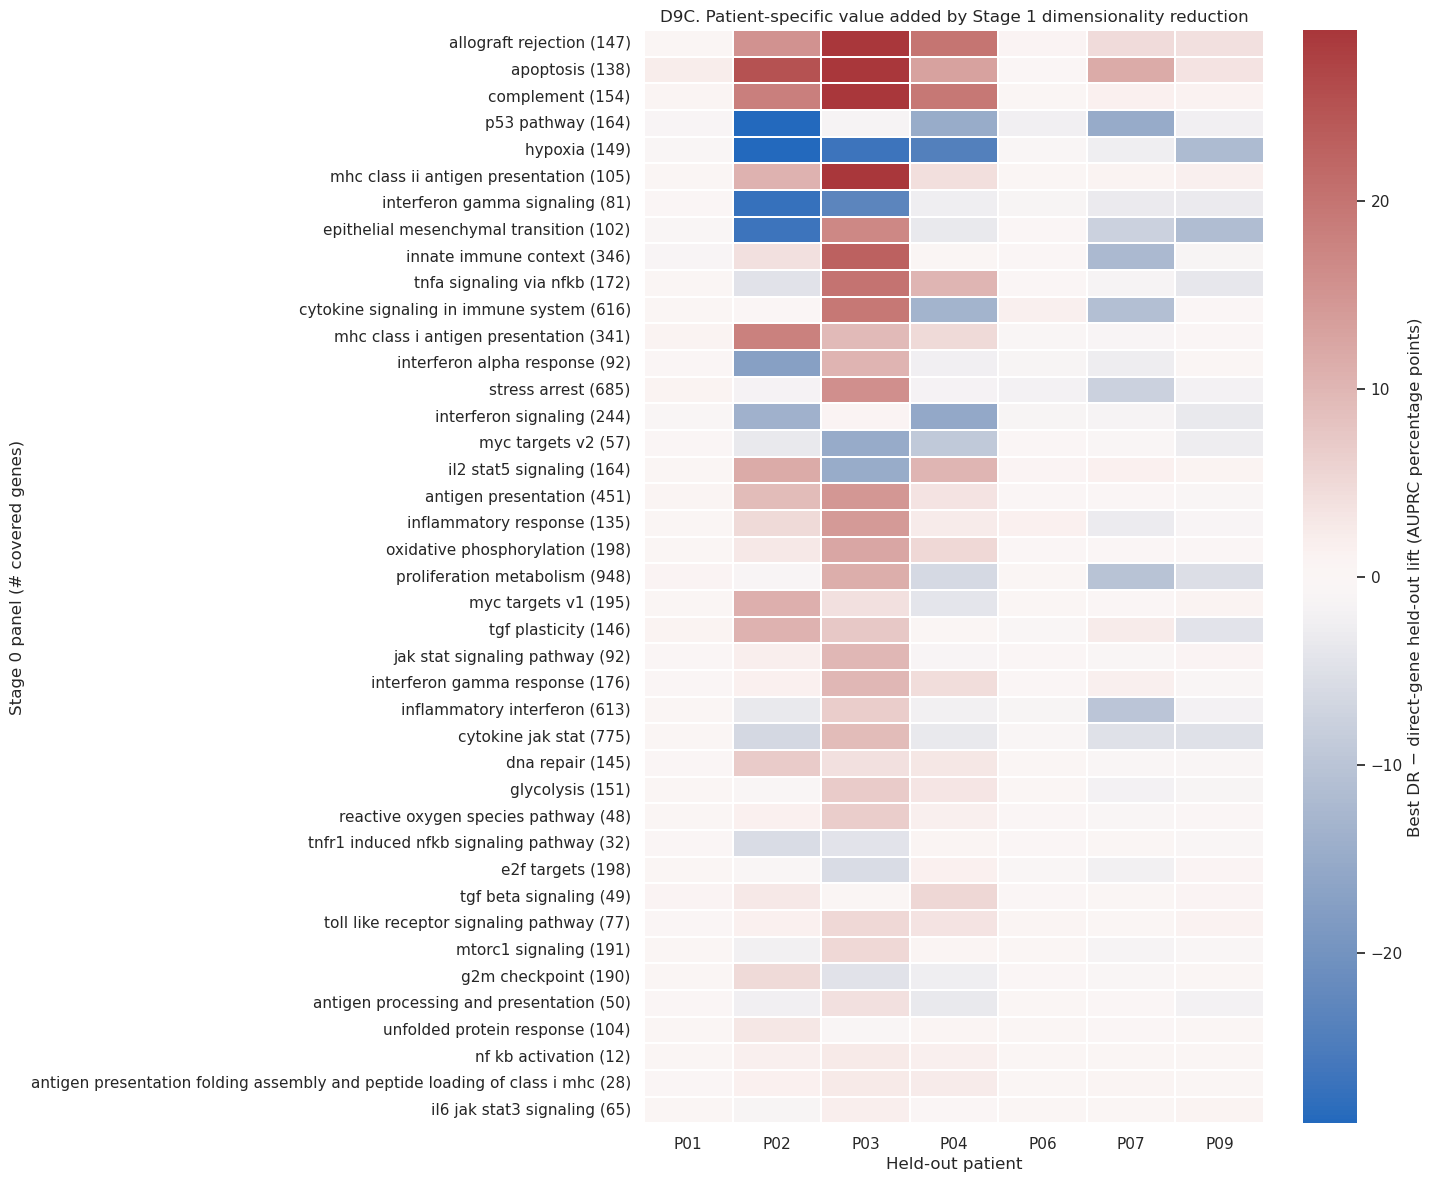

/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/meeting_followup_v1/D9D_priority_panels_direct_gene_vs_best_dr.png


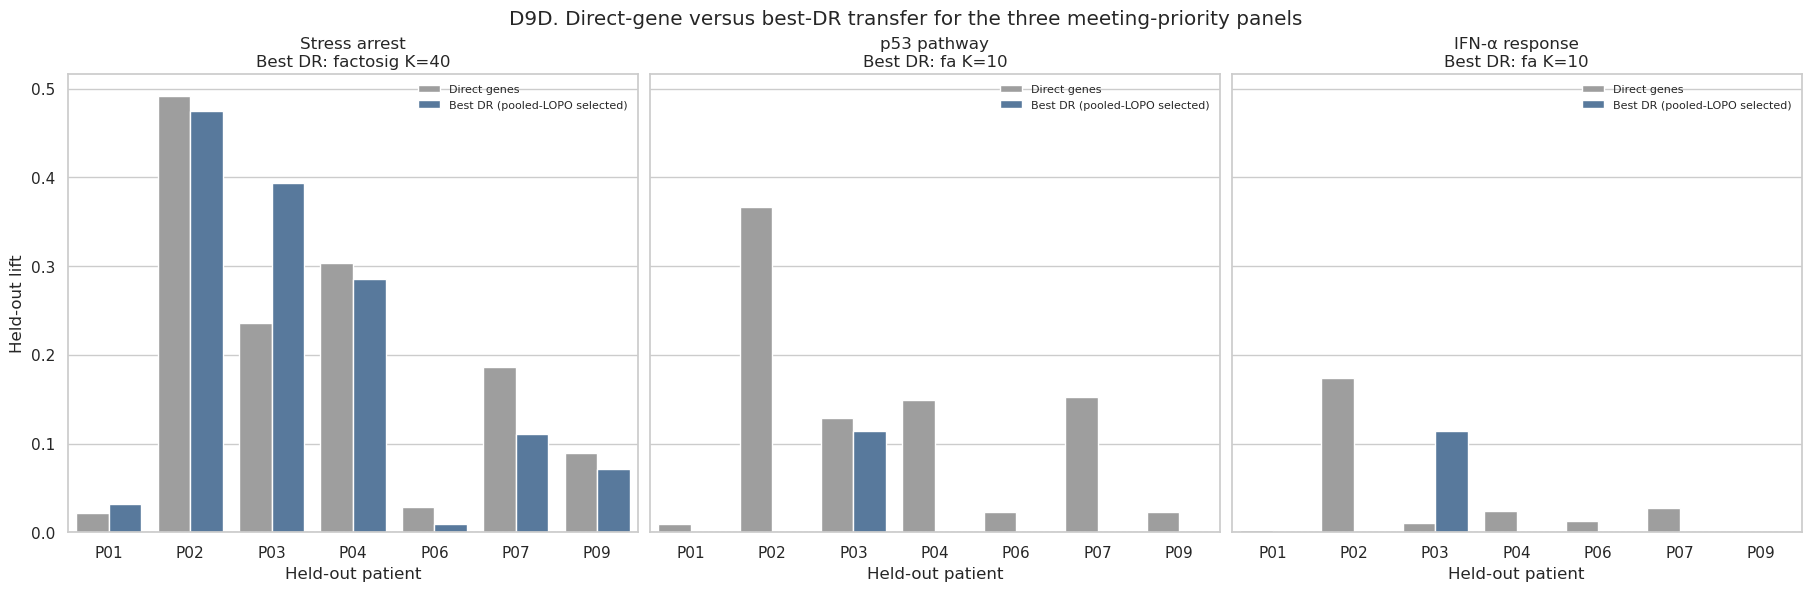

/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/meeting_followup_v1/D9E_completed_direct_gene_baseline_coverage.png


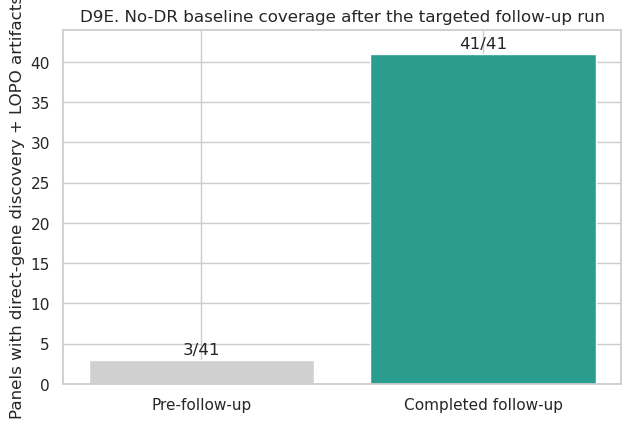

In [10]:
comparison_plot = direct_vs_best_dr.dropna(subset=["best_dr_representation_id"]).copy()

# D9A — pooled LOPO AP comparison.
fig, ax = plt.subplots(figsize=(8.2, 7.2))
sns.scatterplot(
    data=comparison_plot,
    x="direct_pooled_lopo_ap",
    y="best_dr_pooled_lopo_ap",
    hue="best_dr_method",
    style="best_dr_method",
    s=85,
    ax=ax,
)
lims = [
    min(comparison_plot["direct_pooled_lopo_ap"].min(), comparison_plot["best_dr_pooled_lopo_ap"].min()) - 0.01,
    max(comparison_plot["direct_pooled_lopo_ap"].max(), comparison_plot["best_dr_pooled_lopo_ap"].max()) + 0.01,
]
ax.plot(lims, lims, color="0.4", ls="--", lw=1)
for _, row in comparison_plot.nlargest(6, "dr_value_added_pooled_lopo_ap").iterrows():
    ax.annotate(row["short_panel_label"], (row["direct_pooled_lopo_ap"], row["best_dr_pooled_lopo_ap"]), xytext=(4, 4), textcoords="offset points", fontsize=8)
ax.set_xlim(lims)
ax.set_ylim(lims)
ax.set_xlabel("Direct-gene pooled LOPO AP")
ax.set_ylabel("Best-DR pooled LOPO AP")
ax.set_title("D9A. Stage 1 value added on the global regularization-selection criterion")
ax.legend(title="Best DR method", frameon=False)
d9a_png = save_figure(fig, "D9A_direct_gene_vs_best_dr_pooled_lopo_ap")
plt.show()

# D9B — patient lower-tail comparison.
fig, ax = plt.subplots(figsize=(8.2, 7.2))
sns.scatterplot(
    data=comparison_plot,
    x=100 * comparison_plot["direct_p20_lift"],
    y=100 * comparison_plot["best_dr_p20_lift"],
    hue="best_dr_method",
    style="best_dr_method",
    s=85,
    ax=ax,
)
low = 100 * min(comparison_plot["direct_p20_lift"].min(), comparison_plot["best_dr_p20_lift"].min()) - 0.5
high = 100 * max(comparison_plot["direct_p20_lift"].max(), comparison_plot["best_dr_p20_lift"].max()) + 0.5
ax.plot([low, high], [low, high], color="0.4", ls="--", lw=1)
for _, row in comparison_plot.nlargest(6, "dr_value_added_p20_lift").iterrows():
    ax.annotate(row["short_panel_label"], (100 * row["direct_p20_lift"], 100 * row["best_dr_p20_lift"]), xytext=(4, 4), textcoords="offset points", fontsize=8)
ax.set_xlim(low, high)
ax.set_ylim(low, high)
ax.set_xlabel("Direct-gene P20 held-out lift (AUPRC pp)")
ax.set_ylabel("Best-DR P20 held-out lift (AUPRC pp)")
ax.set_title("D9B. Stage 1 value added on the seven-patient lower-tail floor")
ax.legend(title="Best DR method", frameon=False)
d9b_png = save_figure(fig, "D9B_direct_gene_vs_best_dr_p20_lift")
plt.show()

# D9C — patient-specific DR value-added heatmap.
value_added_matrix = direct_vs_best_dr_patient.pivot(
    index="panel_label_with_genes",
    columns="heldout_patient",
    values="dr_value_added_patient_lift",
).reindex(columns=SUPPORTED_PATIENTS)
value_added_order = value_added_matrix.abs().max(axis=1).sort_values(ascending=False).index
value_added_matrix = value_added_matrix.loc[value_added_order]
value_vmax = max(float(np.nanpercentile(np.abs(value_added_matrix.to_numpy()), 98)), 0.01)
fig, ax = plt.subplots(figsize=(10.0, 14.2))
sns.heatmap(
    100 * value_added_matrix,
    cmap="vlag",
    center=0,
    vmin=-100 * value_vmax,
    vmax=100 * value_vmax,
    linewidths=0.25,
    linecolor="white",
    cbar_kws={"label": "Best DR − direct-gene held-out lift (AUPRC percentage points)"},
    ax=ax,
)
ax.set_xlabel("Held-out patient")
ax.set_ylabel("Stage 0 panel (# covered genes)")
ax.set_title("D9C. Patient-specific value added by Stage 1 dimensionality reduction")
d9c_png = save_figure(fig, "D9C_best_dr_minus_direct_gene_patient_lift")
plt.show()

# D9D — priority panels, direct versus globally selected best DR per patient.
priority_panel_ids = [
    "single_group__stress_arrest",
    "single_geneset__hallmark_p53_pathway",
    IFNA_PANEL,
]
priority_names = {
    "single_group__stress_arrest": "Stress arrest",
    "single_geneset__hallmark_p53_pathway": "p53 pathway",
    IFNA_PANEL: "IFN-α response",
}
fig, axes = plt.subplots(1, 3, figsize=(18, 5.8), sharey=True, constrained_layout=True)
for ax, panel_id in zip(axes, priority_panel_ids):
    subset = direct_vs_best_dr_patient.loc[direct_vs_best_dr_patient["stage0_panel_id"].eq(panel_id)].copy()
    long = pd.concat(
        [
            subset[["heldout_patient", "heldout_lift_direct"]].rename(columns={"heldout_lift_direct": "heldout_lift"}).assign(representation="Direct genes"),
            subset[["heldout_patient", "heldout_lift_best_dr"]].rename(columns={"heldout_lift_best_dr": "heldout_lift"}).assign(representation="Best DR (pooled-LOPO selected)"),
        ],
        ignore_index=True,
    )
    sns.barplot(
        data=long,
        x="heldout_patient",
        y="heldout_lift",
        hue="representation",
        order=SUPPORTED_PATIENTS,
        palette=["#9E9E9E", "#4C78A8"],
        ax=ax,
    )
    best_row = comparison_plot.loc[comparison_plot["stage0_panel_id"].eq(panel_id)].iloc[0]
    ax.axhline(0, color="0.4", lw=0.8, ls="--")
    ax.set_xlabel("Held-out patient")
    ax.set_ylabel("Held-out lift")
    ax.set_title(f"{priority_names[panel_id]}\nBest DR: {best_row['best_dr_method']} K={int(best_row['best_dr_k'])}")
    ax.legend(frameon=False, fontsize=8)
fig.suptitle("D9D. Direct-gene versus best-DR transfer for the three meeting-priority panels")
d9d_png = save_figure(fig, "D9D_priority_panels_direct_gene_vs_best_dr")
plt.show()

# D9E — completed direct-gene coverage.
fig, ax = plt.subplots(figsize=(7.2, 4.6))
ax.bar(["Pre-follow-up", "Completed follow-up"], [3, 41], color=["#D0D0D0", "#2A9D8F"])
for x, value in enumerate([3, 41]):
    ax.text(x, value + 0.7, f"{value}/41", ha="center")
ax.set_ylim(0, 44)
ax.set_ylabel("Panels with direct-gene discovery + LOPO artifacts")
ax.set_title("D9E. No-DR baseline coverage after the targeted follow-up run")
d9e_png = save_figure(fig, "D9E_completed_direct_gene_baseline_coverage")
plt.show()

In [11]:
d9_contracts = pd.DataFrame(
    [
        plot_contract("D9A", "Direct genes versus best DR pooled LOPO AP", "Does Stage 1 improve the criterion used for global regularization selection?", "Select one direct and one best-DR model per panel by pooled LOPO AP and compare them.", "panel", "pooled-cell LOPO average precision", "Stage 1 value added is panel-dependent rather than guaranteed.", "Best-DR selection across methods/K is optimistic and should be validated in the expanded cohort."),
        plot_contract("D9B", "Direct genes versus best DR P20 lift", "Does Stage 1 improve the lower-tail patient transfer floor?", "Evaluate globally selected direct and DR models per patient and compare their P20 AP lift.", "panel", "20th percentile of seven patient AP-minus-prevalence lifts", "P20 exposes whether pooled gains survive lower-performing patients.", "Seven-patient quantiles are coarse and uncertain."),
        plot_contract("D9C", "Patient-specific DR value added", "For which panel/patient pairs does DR beat raw genes?", "Subtract direct-gene lift from the globally selected best-DR representation within patient and panel.", "panel × held-out patient", "best-DR minus direct AP lift in percentage points", "DR gains and losses are strongly patient- and panel-specific.", "Best DR is selected in the same cohort and lacks nested representation selection."),
        plot_contract("D9D", "Priority-panel direct versus DR transfer", "What does the no-DR comparison show for stress arrest, p53, and IFN-alpha?", "Plot direct and pooled-LOPO-selected best DR held-out lift for each supported patient.", "panel × held-out patient × representation", "AP minus patient prevalence", "The three meeting-priority panels have concrete patient-level no-DR comparators.", "No external cohort and no patient-specific uncertainty intervals."),
        plot_contract("D9E", "Completed direct-gene coverage", "Was the no-DR baseline gap closed?", "Validate 41 direct Stage 0 rows and merged discovery/LOPO scorecards from eight GPU shards.", "panel", "completed artifact coverage", "All 41 panels now have direct-gene discovery and LOPO paths.", "Patient-specific direct models were intentionally not run."),
    ]
)
plot_contracts = pd.concat([plot_contracts.loc[~plot_contracts["plot_id"].str.startswith("D9")], d9_contracts], ignore_index=True)
plot_contracts.to_csv(plot_contracts_path, index=False)

n_comparable_panels = len(comparison_plot)
n_dr_better_pooled = int((comparison_plot["dr_value_added_pooled_lopo_ap"] > 0).sum())
n_dr_better_median = int((comparison_plot["dr_value_added_median_lift"] > 0).sum())
n_dr_better_p20 = int((comparison_plot["dr_value_added_p20_lift"] > 0).sum())
priority_comparison = comparison_plot.loc[comparison_plot["stage0_panel_id"].isin(priority_panel_ids)].copy()

report_lines = [
    "# Old34 meeting follow-up findings",
    "",
    f"Generated: {datetime.now(timezone.utc).isoformat()}",
    "",
    "## Metric validity",
    "",
    "- Stage 2 uses `sklearn.metrics.average_precision_score`.",
    "- Constant all-healthy and all-malignant scores both reproduce malignant prevalence exactly as AP.",
    "- Hard policies differ in sensitivity/specificity/accuracy, not AP ranking baseline.",
    "- Retain raw lift `AP - prevalence`; add normalized lift `(AP - prevalence)/(1 - prevalence)`.",
    f"- Median within-representation rho(AP, prevalence): {association_lookup[('heldout_auprc', 'patient_prevalence')]:.3f}.",
    f"- Median within-representation rho(raw lift, prevalence): {association_lookup[('heldout_lift', 'patient_prevalence')]:.3f}.",
    f"- Median within-representation rho(normalized lift, prevalence): {association_lookup[('normalized_heldout_lift', 'patient_prevalence')]:.3f}.",
    "- Raw and normalized lift remain positively associated with prevalence in this seven-patient cohort; subtraction does not prove the effect is biological.",
    "",
    "## Donor/recipient transparency",
    "",
    f"- Exact filtered MRD/CITE binary cohort: {len(mrd_obs):,} cells.",
    f"- Recipient-healthy counts across patients: {dict(zip(patient_composition['patient_id'], patient_composition['n_healthy_recipient']))}.",
    "- Donor healthy cells are the practical comparator, but donor sensitivity remains a required targeted rerun.",
    "",
    "## IFN-alpha PCA40 versus FA40",
    "",
    f"- Maximum AP reconstruction error from stored scores/coefficients: {ifna_reconstruction['absolute_reconstruction_error'].max():.2e}.",
    f"- PCA driver: {pca_driver_id}; it is the only active PCA factor in the focus folds.",
    f"- Most correlated FA factors: {', '.join(fa_driver_candidates['fa_feature_id'])}.",
    f"- Degenerate FA score factors: {', '.join(fa_degenerate)}.",
    "- PCA factor 008 remains selected in P02/P03/P04/P07; FA factor 007 remains selected only in P03/P04.",
    "",
    "## No-DR baseline result",
    "",
    "- Completed direct-gene standardized features, discovery paths, and LOPO paths for 41/41 panels.",
    f"- Comparable panels with at least one DR representation: {n_comparable_panels}.",
    f"- Best DR exceeds direct genes on pooled LOPO AP in {n_dr_better_pooled}/{n_comparable_panels} panels.",
    f"- Best DR exceeds direct genes on median held-out lift in {n_dr_better_median}/{n_comparable_panels} panels.",
    f"- Best DR exceeds direct genes on P20 held-out lift in {n_dr_better_p20}/{n_comparable_panels} panels.",
    f"- Median DR value added: pooled AP {comparison_plot['dr_value_added_pooled_lopo_ap'].median():.4f}, median lift {comparison_plot['dr_value_added_median_lift'].median():.4f}, P20 lift {comparison_plot['dr_value_added_p20_lift'].median():.4f}.",
    "- The best-DR comparator is selected in-sample across methods/K; treat it as exploratory until nested or external validation.",
    "",
    "## Donor sensitivity boundary",
    "",
    "- The previously implemented legacy downsampler acts after global FA and therefore cannot test factor-loading stability.",
    "- A valid follow-up needs two linked analyses: fixed-basis training-only donor downsampling with full held-out evaluation, plus targeted pre-DR basis refits and aligned loading stability.",
]
report_path.write_text("\n".join(report_lines) + "\n")

manifest.update(
    {
        "created_utc": datetime.now(timezone.utc).isoformat(),
        "model_reruns": True,
        "rerun_scope": "41 direct-gene representations; discovery and LOPO only; 65 regularization settings; 8 GPU shards",
        "direct_gene_run": {
            "branch": DIRECT_BRANCH,
            "run_id": DIRECT_RUN_ID,
            "panels": 41,
            "discovery_rows": int(len(direct_lopo)),
            "lopo_rows": int(len(direct_lopo)),
            "lopo_patient_rows": int(len(direct_lopo_patient)),
            "shard_failures": launcher_manifest["outputs"]["failures"],
            "patient_specific_run": False,
        },
        "counts": {
            **manifest["counts"],
            "direct_gene_panels_completed": 41,
            "direct_gene_selected_patient_rows": len(direct_patient_selected),
            "direct_gene_comparable_dr_panels": n_comparable_panels,
            "plot_contracts": len(plot_contracts),
        },
        "source_files": {name: source_signature(path) for name, path in SOURCE_PATHS.items()},
    }
)
manifest_path.write_text(json.dumps(manifest, indent=2) + "\n")

artifact_paths = sorted(
    path
    for root in [TABLE_DIR, FIGURE_DIR]
    for path in root.rglob("*")
    if path.is_file() and path not in {ledger_path, validation_path}
)
ledger_records = []
for path in artifact_paths:
    if path.suffix.lower() == ".csv":
        artifact_type = "table"
        n_rows = len(pd.read_csv(path, low_memory=False))
    elif path.suffix.lower() in {".png", ".pdf"}:
        artifact_type = "figure"
        n_rows = np.nan
    elif path.suffix.lower() == ".md":
        artifact_type = "report"
        n_rows = np.nan
    else:
        artifact_type = "manifest"
        n_rows = np.nan
    ledger_records.append(
        {
            "artifact_id": path.stem,
            "artifact_type": artifact_type,
            "relative_path": str(path.relative_to(EXP_DIR)),
            "size_bytes": path.stat().st_size,
            "sha256": sha256_file(path),
            "n_rows_if_csv": n_rows,
            "modified_utc": datetime.fromtimestamp(path.stat().st_mtime, timezone.utc).isoformat(),
        }
    )
artifact_ledger = pd.DataFrame(ledger_records).sort_values(["artifact_type", "relative_path"]).reset_index(drop=True)
artifact_ledger.to_csv(ledger_path, index=False)

assert len(direct_selected) == 41
assert len(direct_patient_selected) == 41 * 7
assert len(direct_vs_best_dr) == 41
assert n_comparable_panels >= 40
assert len(plot_contracts) == 26
assert len(GENERATED_FIGURES) == 52
assert launcher_manifest["outputs"]["merge"]["discovery_rows"] == 41 * 65
assert launcher_manifest["outputs"]["merge"]["lopo_rows"] == 41 * 65
assert launcher_manifest["outputs"]["failures"] == []
for path in artifact_paths + [ledger_path]:
    assert path.exists() and path.stat().st_size > 0

disk = shutil.disk_usage(EXP_DIR)
validation = {
    "validated_utc": datetime.now(timezone.utc).isoformat(),
    "status": "pass",
    "metric_and_analysis_model_reruns": False,
    "direct_gene_targeted_model_rerun": True,
    "direct_gene_run_id": DIRECT_RUN_ID,
    "direct_gene_shard_failures": launcher_manifest["outputs"]["failures"],
    "mrd_binary_cells": len(mrd_obs),
    "patient_metric_rows": len(patient_metrics),
    "representation_count_original": patient_metrics["representation_id"].nunique(),
    "direct_gene_panels_completed": len(direct_selected),
    "direct_gene_selected_patient_rows": len(direct_patient_selected),
    "ifna_max_ap_reconstruction_error": float(ifna_reconstruction["absolute_reconstruction_error"].max()),
    "plot_contract_rows": len(plot_contracts),
    "tracked_artifacts_excluding_ledger_and_validation": len(artifact_ledger),
    "tracked_bytes_excluding_ledger_and_validation": int(artifact_ledger["size_bytes"].sum()),
    "filesystem_free_gib": disk.free / 1024**3,
}
validation_path.write_text(json.dumps(validation, indent=2) + "\n")

print("Validation: PASS")
print(f"Best DR > direct: pooled={n_dr_better_pooled}/{n_comparable_panels}, median={n_dr_better_median}/{n_comparable_panels}, P20={n_dr_better_p20}/{n_comparable_panels}")
print("Tracked artifacts including ledger and validation:", len(artifact_ledger) + 2)
display(priority_comparison[["short_panel_label", "direct_pooled_lopo_ap", "best_dr_method", "best_dr_k", "best_dr_pooled_lopo_ap", "dr_value_added_pooled_lopo_ap", "direct_p20_lift", "best_dr_p20_lift", "dr_value_added_p20_lift"]])

Validation: PASS
Best DR > direct: pooled=38/41, median=16/41, P20=17/41
Tracked artifacts including ledger and validation: 76


,short_panel_label,direct_pooled_lopo_ap,best_dr_method,best_dr_k,best_dr_pooled_lopo_ap,dr_value_added_pooled_lopo_ap,direct_p20_lift,best_dr_p20_lift,dr_value_added_p20_lift
12,interferon alpha response,0.048606,fa,10,0.200924,0.152318,0.003720,-4.649059e-17,-0.003720
18,p53 pathway,0.070474,fa,10,0.175180,0.104707,0.023085,-4.649059e-17,-0.023085
39,stress arrest,0.110621,factosig,40,0.209094,0.098474,0.040794,3.972980e-02,-0.001065
